<a href="https://colab.research.google.com/github/mshitie/quantitative_XAI/blob/main/BUS_accuracy_vs_interpretability_multiobjective.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Accuracy vs. Interpretability in Breast Ultrasound (BUSI): Multi-Objective Learning
Objectives: **(1)** diagnostic loss (CE) and **(2)** explanation loss (CAM / lesion-mask overlap).
Optimizers compared: weighted-sum (lambda sweep), MGDA, PCGrad, preference-conditioned Pareto model, NSGA-II (hyper-parameter level).
Extras: mask-dilation / loss ablations, faithfulness (deletion/insertion), sanity checks, shortcut (confounder) experiment, hypervolume, statistics.

**Runtime > Change runtime type > GPU (T4)** before running. Set `QUICK = True` in cell 2 for a fast smoke test.

In [1]:
# ---------- 1. Download + unzip (BUSI from Kaggle) ----------
!pip install -q kaggle pymoo scikit-learn scipy seaborn
import os
if not os.path.exists('/content/kaggle.json'):
    # Option A: pick kaggle.json in the file dialog. Option B: drag it into the Files sidebar,
    # or copy it from Drive with: !cp /content/drive/MyDrive/<your path>/kaggle.json /content/kaggle.json
    from google.colab import files
    files.upload()
assert os.path.exists('/content/kaggle.json'), "kaggle.json still not found in /content"
os.environ['KAGGLE_CONFIG_DIR'] = '/content'
!chmod 600 /content/kaggle.json
!kaggle datasets download -d aryashah2k/breast-ultrasound-images-dataset
!unzip -q -o breast-ultrasound-images-dataset.zip -d busi
!ls busi

Saving kaggle.json to kaggle.json
Dataset URL: https://www.kaggle.com/datasets/aryashah2k/breast-ultrasound-images-dataset
License(s): CC0-1.0
100% 195M/195M [00:01<00:00, 140MB/s]

Dataset_BUSI_with_GT


In [2]:
# ---------- 2. Imports + configuration ----------
import os, glob, random, copy, time, math, shutil, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from PIL import Image
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, roc_curve
from scipy.stats import spearmanr, wilcoxon
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='talk')

QUICK = False            # True = tiny smoke test (1 seed, 3 epochs)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
S = 224                  # image size
CFG = dict(
    BS=16, LR=3e-4, WD=1e-4, PRETRAINED=True,
    EPOCHS=3 if QUICK else 15,
    SEEDS=[0] if QUICK else [0, 1, 2],
    LAMBDAS=[0.1, 0.5, 1, 2, 5],               # weighted-sum sweep (lambda=0 -> baseline)
    PREF_GRID=[0.0, 0.17, 0.33, 0.5, 0.67, 0.83, 1.0],   # weight on explanation objective at inference
    RUN_NSGA2=True, NSGA_POP=4 if QUICK else 6, NSGA_GEN=2 if QUICK else 3, NSGA_EPOCHS=2 if QUICK else 6,
    RUN_CONFOUNDER=True,
    FAITH_N=60,
)
OUT = 'results'; FIG = f'{OUT}/figs'
os.makedirs(FIG, exist_ok=True)
print('device:', DEVICE, '| config:', CFG)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

device: cuda | config: {'BS': 16, 'LR': 0.0003, 'WD': 0.0001, 'PRETRAINED': True, 'EPOCHS': 15, 'SEEDS': [0, 1, 2], 'LAMBDAS': [0.1, 0.5, 1, 2, 5], 'PREF_GRID': [0.0, 0.17, 0.33, 0.5, 0.67, 0.83, 1.0], 'RUN_NSGA2': True, 'NSGA_POP': 6, 'NSGA_GEN': 3, 'NSGA_EPOCHS': 6, 'RUN_CONFOUNDER': True, 'FAITH_N': 60}


label
benign       437
malignant    210
Name: count, dtype: int64
usable images: 647
{'Xtr': (452, 1, 224, 224), 'Xva': (97, 1, 224, 224), 'Xte': (98, 1, 224, 224)}


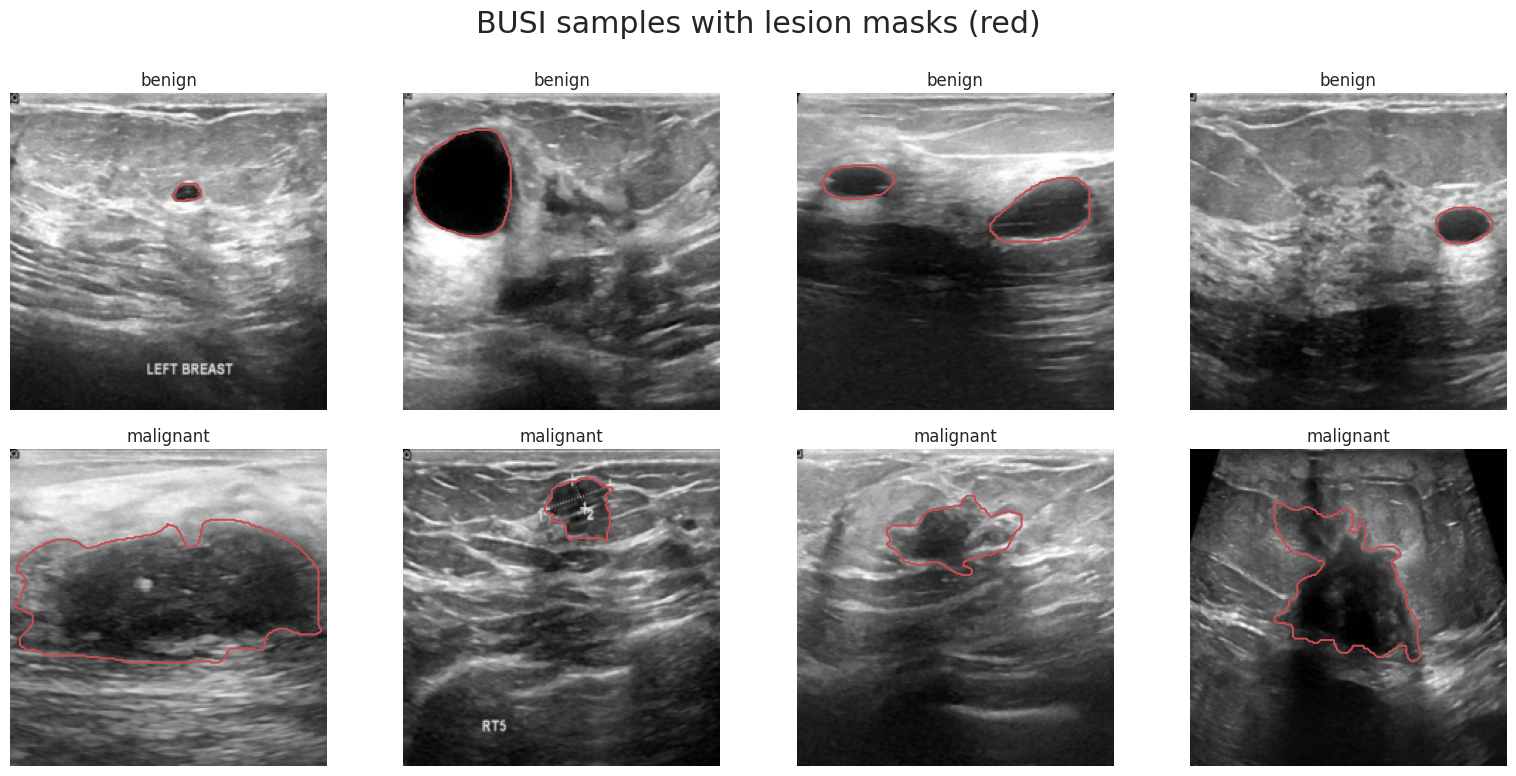

In [3]:
# ---------- 3. Build dataframe (benign vs malignant; masks merged) ----------
ROOT = None
for p in glob.glob('busi/**/benign', recursive=True):
    ROOT = os.path.dirname(p); break
assert ROOT is not None, 'BUSI folder not found'
rows = []
for cls in ['benign', 'malignant']:                       # 'normal' has empty masks -> excluded
    for f in sorted(glob.glob(f'{glob.escape(ROOT)}/{cls}/*.png')):
        if '_mask' in os.path.basename(f): continue
        masks = glob.glob(glob.escape(f[:-4]) + '_mask*.png')
        if len(masks): rows.append(dict(path=f, label=int(cls == 'malignant'), masks=masks))
df = pd.DataFrame(rows)
print(df.label.value_counts().rename({0: 'benign', 1: 'malignant'}))

def load_item(r):
    img = np.array(Image.open(r.path).convert('L').resize((S, S), Image.BILINEAR))
    m = np.zeros((S, S), np.float32)
    for mp in r.masks:
        m = np.maximum(m, (np.array(Image.open(mp).convert('L').resize((S, S), Image.NEAREST)) > 127).astype(np.float32))
    return img, m

items = [load_item(r) for r in df.itertuples()]
X_all = torch.from_numpy(np.stack([i[0] for i in items]))[:, None]           # uint8 (N,1,S,S)
M_all = torch.from_numpy(np.stack([i[1] for i in items]))[:, None]           # float (N,1,S,S)
y_all = torch.tensor(df.label.values)
keep = M_all.flatten(1).sum(1) > 0
X_all, M_all, y_all = X_all[keep], M_all[keep], y_all[keep]
N = len(y_all); print('usable images:', N)

# fixed stratified split 70/15/15 (same test set for every run)
idx = np.arange(N)
i_tr, i_tmp = train_test_split(idx, test_size=0.30, stratify=y_all.numpy(), random_state=42)
i_va, i_te = train_test_split(i_tmp, test_size=0.50, stratify=y_all.numpy()[i_tmp], random_state=42)
def make_data(X, M, y):
    d = {}
    for k, ii in [('tr', i_tr), ('va', i_va), ('te', i_te)]:
        d['X' + k], d['M' + k], d['y' + k] = X[ii].to(DEVICE), M[ii].to(DEVICE), y[ii].to(DEVICE)
    return d
DATA = make_data(X_all, M_all, y_all)
print({k: tuple(v.shape) for k, v in DATA.items() if k.startswith('X')})

# dataset overview figure
fig, ax = plt.subplots(2, 4, figsize=(16, 8))
for c in range(2):
    sel = np.where(y_all.numpy() == c)[0][:4]
    for j, s in enumerate(sel):
        ax[c, j].imshow(X_all[s, 0], cmap='gray'); ax[c, j].contour(M_all[s, 0], [0.5], colors='r', linewidths=1.5)
        ax[c, j].set_title(['benign', 'malignant'][c], fontsize=12); ax[c, j].axis('off')
plt.suptitle('BUSI samples with lesion masks (red)'); plt.tight_layout()
plt.savefig(f'{FIG}/00_dataset_samples.png', dpi=200); plt.show()

In [4]:
# ---------- 4. Model, differentiable CAM, losses, GPU augmentation ----------
MEAN = torch.tensor([0.485, 0.456, 0.406], device=DEVICE).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225], device=DEVICE).view(1, 3, 1, 1)
def prep(x01):                                  # x01: (B,1,S,S) in [0,1]
    return (x01.repeat(1, 3, 1, 1) - MEAN) / STD

class Net(nn.Module):
    """ResNet-18 + GAP + FC. For GAP->FC nets, Grad-CAM at the last conv layer == CAM (up to a constant),
    so we train with the closed-form CAM (no second-order gradients). cond=True adds FiLM conditioning on a
    preference vector (Pareto-front learning: one model, many trade-offs)."""
    def __init__(self, cond=False):
        super().__init__()
        r = torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.DEFAULT if CFG['PRETRAINED'] else None)
        self.stem = nn.Sequential(r.conv1, r.bn1, r.relu, r.maxpool, r.layer1, r.layer2, r.layer3, r.layer4)
        self.fc = nn.Linear(512, 2); self.cond = cond
        if cond:
            self.film = nn.Sequential(nn.Linear(2, 64), nn.ReLU(), nn.Linear(64, 1024))
            nn.init.zeros_(self.film[-1].weight); nn.init.zeros_(self.film[-1].bias)
    def forward(self, x, pref=None):
        f = self.stem(x)
        if self.cond:
            g, b = self.film(pref).chunk(2, 1)
            f = f * (1 + g[:, :, None, None]) + b[:, :, None, None]
        return self.fc(f.mean((2, 3))), f

def cam_raw(f, W, cls):                          # class-specific CAM at feature resolution
    return (f * W[cls][:, :, None, None]).sum(1, keepdim=True)
def up(c): return F.interpolate(c, size=(S, S), mode='bilinear', align_corners=False)
def norm_cam(c):
    c = F.relu(c); return c / (c.flatten(1).amax(1)[:, None, None, None] + 1e-6)

def exp_loss(cam, m, kind='dice'):
    inter = (cam * m).flatten(1).sum(1)
    if kind == 'dice':                           # 1 - soft Dice(CAM, mask)
        return (1 - (2 * inter + 1) / (cam.flatten(1).sum(1) + m.flatten(1).sum(1) + 1)).mean()
    return (1 - inter / (cam.flatten(1).sum(1) + 1e-6)).mean()   # 'energy': CAM mass outside mask (RRR-style)

def dilate(m, px):                               # peri-lesional band (radiologists use surrounding tissue)
    return m if px <= 0 else F.max_pool2d(m, 2 * px + 1, 1, px)

def augment(x, m):
    B, dev = x.size(0), x.device
    r = lambda: torch.rand(B, device=dev) * 2 - 1
    ang, sc = r() * 10 * math.pi / 180, 1 + r() * 0.1
    tx, ty = r() * 0.1, r() * 0.1
    flip = (torch.rand(B, device=dev) < 0.5).float() * 2 - 1
    c, s = torch.cos(ang) / sc, torch.sin(ang) / sc
    theta = torch.stack([torch.stack([c * flip, -s, tx], 1), torch.stack([s * flip, c, ty], 1)], 1)
    grid = F.affine_grid(theta, x.shape, align_corners=False)
    x = F.grid_sample(x, grid, padding_mode='reflection', align_corners=False)
    m = (F.grid_sample(m, grid, padding_mode='zeros', align_corners=False) > 0.5).float()
    x = (x * (1 + r().view(B, 1, 1, 1) * 0.2) + r().view(B, 1, 1, 1) * 0.1).clamp(0, 1)
    return x, m

# ---- gradient helpers for MGDA / PCGrad ----
def flat_grads(loss, params):
    gs = torch.autograd.grad(loss, params, retain_graph=True, allow_unused=True)
    return torch.cat([(g if g is not None else torch.zeros_like(p)).reshape(-1) for g, p in zip(gs, params)])
def set_grads(params, g):
    o = 0
    for p in params:
        n = p.numel(); p.grad = g[o:o + n].view_as(p).clone(); o += n
def mgda_alpha(gc, ge):                          # closed-form min-norm point for 2 objectives
    a = ((ge - gc) @ ge) / (((gc - ge) ** 2).sum() + 1e-12)
    return a.clamp(0, 1)
def pcgrad(gc, ge):
    gs, orig = [gc.clone(), ge.clone()], [gc, ge]
    order = [0, 1]; random.shuffle(order)
    for i in order:
        j = 1 - i; d = gs[i] @ orig[j]
        if d < 0: gs[i] -= d / (orig[j] @ orig[j] + 1e-12) * orig[j]
    return gs[0] + gs[1]

In [5]:
# ---------- 5. Prediction, metrics, faithfulness, sanity checks ----------
def _pref(pref, B):
    return None if pref is None else torch.tensor(pref, device=DEVICE, dtype=torch.float32)[None].expand(B, 2)

@torch.no_grad()
def predict(model, X, pref=None, bs=64):
    model.eval(); P, C = [], []
    for i in range(0, len(X), bs):
        x = prep(X[i:i + bs].float() / 255)
        logits, f = model(x, _pref(pref, len(x)))
        pr = F.softmax(logits, 1)
        C.append(norm_cam(up(cam_raw(f, model.fc.weight, pr.argmax(1))))); P.append(pr)
    return torch.cat(P), torch.cat(C)           # predicted-class CAMs

def ece_bins(conf, correct, nb=10):
    edges = np.linspace(0.5, 1.0, nb + 1); b = np.clip(np.digitize(conf, edges[1:-1]), 0, nb - 1)
    acc = np.array([correct[b == k].mean() if (b == k).any() else np.nan for k in range(nb)])
    cf = np.array([conf[b == k].mean() if (b == k).any() else np.nan for k in range(nb)])
    cnt = np.array([(b == k).sum() for k in range(nb)])
    ece = np.nansum(np.abs(acc - cf) * cnt / len(conf))
    return ece, cf, acc, cnt

def compute_metrics(probs, y, cams, M):
    p1, yn = probs[:, 1].cpu().numpy(), y.cpu().numpy(); pred = (p1 >= 0.5).astype(int)
    tp, tn = ((pred == 1) & (yn == 1)).sum(), ((pred == 0) & (yn == 0)).sum()
    fp, fn = ((pred == 1) & (yn == 0)).sum(), ((pred == 0) & (yn == 1)).sum()
    sens, spec = tp / max(tp + fn, 1), tn / max(tn + fp, 1)
    f1 = 2 * tp / max(2 * tp + fp + fn, 1)
    conf = np.maximum(p1, 1 - p1); ece = ece_bins(conf, (pred == yn).astype(float))[0]
    cb = (cams >= 0.5).float()
    inter = (cb * M).flatten(1).sum(1); union = ((cb + M) > 0).float().flatten(1).sum(1)
    iou = inter / union.clamp(min=1)
    dice = 2 * inter / (cb.flatten(1).sum(1) + M.flatten(1).sum(1)).clamp(min=1)
    energy = (cams * M).flatten(1).sum(1) / cams.flatten(1).sum(1).clamp(min=1e-6)
    am = cams.flatten(1).argmax(1); point = M.flatten(1).gather(1, am[:, None])[:, 0]
    out = dict(auc=roc_auc_score(yn, p1), acc=(pred == yn).mean(), sens=sens, spec=spec, f1=f1, ece=ece,
               brier=float(((p1 - yn) ** 2).mean()), iou=iou.mean().item(), dice=dice.mean().item(),
               energy=energy.mean().item(), point=point.mean().item())
    return out, iou.cpu().numpy()

def _trapz(y, x): return float(np.sum((y[1:] + y[:-1]) / 2 * np.diff(x)))

@torch.no_grad()
def faithfulness(model, X, probs, cams, pref=None, n=60, patch=16):
    """Deletion (lower=better) / insertion (higher=better) AUC of predicted-class probability."""
    n = min(n, len(X)); x = prep(X[:n].float() / 255); pc = probs[:n].argmax(1)
    g = F.avg_pool2d(cams[:n], patch).flatten(1); P = g.shape[1]
    rank = g.argsort(1, descending=True).argsort(1)
    blur = F.avg_pool2d(F.pad(x, (10, 10, 10, 10), mode='reflect'), 21, 1)
    fr = np.linspace(0, 1, 15); dl, ins = [], []
    pr_ = _pref(pref, n)
    for f in fr:
        k = int(round(f * P))
        keepm = F.interpolate((rank < k).float().view(n, 1, S // patch, S // patch), scale_factor=patch, mode='nearest')
        pd_ = F.softmax(model(x * (1 - keepm), pr_)[0], 1)[torch.arange(n), pc]
        pi_ = F.softmax(model(blur * (1 - keepm) + x * keepm, pr_)[0], 1)[torch.arange(n), pc]
        dl.append(pd_.mean().item()); ins.append(pi_.mean().item())
    return _trapz(np.array(dl), fr), _trapz(np.array(ins), fr)

def randomization_check(model, X, pref=None, n=50):
    """Adebayo-style sanity check: re-initialise layer4 + fc; CAMs should change (low |Spearman|)."""
    m2 = copy.deepcopy(model)
    for mod in [m2.stem[7], m2.fc]:
        for l in mod.modules():
            if hasattr(l, 'reset_parameters'): l.reset_parameters()
    _, c1 = predict(model, X[:n], pref); _, c2 = predict(m2, X[:n], pref)
    a, b = F.avg_pool2d(c1, 16).flatten(1).cpu().numpy(), F.avg_pool2d(c2, 16).flatten(1).cpu().numpy()
    rho = [abs(spearmanr(a[i], b[i])[0]) for i in range(len(a)) if a[i].std() > 0 and b[i].std() > 0]
    return float(np.nanmean(rho))

def gradcam_equivalence(model, X, n=16):
    """Verify true Grad-CAM (autograd) == closed-form CAM used in training."""
    model.eval(); x = prep(X[:n].float() / 255)
    with torch.enable_grad():
        logits, f = model(x); pc = logits.argmax(1)
        g = torch.autograd.grad(logits[torch.arange(len(x)), pc].sum(), f)[0]
        gc = F.relu((g.mean((2, 3), keepdim=True) * f).sum(1, keepdim=True)).detach()
    cc = F.relu(cam_raw(f, model.fc.weight, pc)).detach()
    a, b = gc.flatten(1), cc.flatten(1)
    return F.cosine_similarity(a, b, dim=1).mean().item()

In [6]:
# ---------- 6. Training (weighted-sum, MGDA, PCGrad, preference-conditioned) ----------
def train_run(method, lam, dil, kind, seed, data, epochs=None, lr=None, verbose=False):
    """method: 'ws' (loss=Lc+lam*Le; lam=0 -> baseline) | 'mgda' | 'pcgrad' | 'pref'."""
    epochs = epochs or CFG['EPOCHS']; lr = lr or CFG['LR']
    set_seed(seed)
    model = Net(cond=(method == 'pref')).to(DEVICE)
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=lr, weight_decay=CFG['WD'])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    ntr = len(data['ytr']); cnt = torch.bincount(data['ytr'], minlength=2).float()
    cw = (ntr / (2 * cnt)).to(DEVICE); hist = []
    for ep in range(epochs):
        model.train(); perm = torch.randperm(ntr, device=DEVICE); acc = dict(Lc=[], Le=[], cos=[], alpha=[])
        for i in range(0, ntr, CFG['BS']):
            idx = perm[i:i + CFG['BS']]
            if len(idx) < 4: continue
            x, m = augment(data['Xtr'][idx].float() / 255, data['Mtr'][idx]); y = data['ytr'][idx]
            r = None
            if method == 'pref':
                r = torch.distributions.Dirichlet(torch.ones(2)).sample().to(DEVICE)
            logits, f = model(prep(x), None if r is None else r[None].expand(len(idx), 2))
            Lc = F.cross_entropy(logits, y, weight=cw)
            cam = norm_cam(up(cam_raw(f, model.fc.weight, y)))      # CAM of the true class
            Le = exp_loss(cam, dilate(m, dil), kind)
            if method == 'ws':
                loss = Lc + lam * Le; opt.zero_grad(); loss.backward()
            elif method == 'pref':
                loss = r[0] * Lc + r[1] * Le; opt.zero_grad(); loss.backward()
            else:
                gc, ge = flat_grads(Lc, params), flat_grads(Le, params)
                acc['cos'].append(F.cosine_similarity(gc, ge, dim=0).item())
                if method == 'mgda':
                    a = mgda_alpha(gc, ge); g = a * gc + (1 - a) * ge; acc['alpha'].append(a.item())
                else:
                    g = pcgrad(gc, ge)
                opt.zero_grad(); set_grads(params, g)
            torch.nn.utils.clip_grad_norm_(params, 5.0); opt.step()
            acc['Lc'].append(Lc.item()); acc['Le'].append(Le.item())
        sched.step()
        vp = [0.5, 0.5] if method == 'pref' else None
        pv, cv = predict(model, data['Xva'], vp); mv, _ = compute_metrics(pv, data['yva'], cv, data['Mva'])
        h = dict(ep=ep + 1, Lc=np.mean(acc['Lc']), Le=np.mean(acc['Le']), val_auc=mv['auc'], val_iou=mv['iou'],
                 cos=np.mean(acc['cos']) if acc['cos'] else np.nan, alpha=np.mean(acc['alpha']) if acc['alpha'] else np.nan)
        hist.append(h)
        if verbose: print({k: round(v, 4) for k, v in h.items()})
    return model, pd.DataFrame(hist)

# quick sanity: one short run, verifying CAM == Grad-CAM
t0 = time.time()
_m, _h = train_run('ws', 1.0, 0, 'dice', 0, DATA, epochs=2, verbose=True)
print('Grad-CAM vs closed-form CAM cosine:', round(gradcam_equivalence(_m, DATA['Xte']), 4), f'| {time.time() - t0:.0f}s for 2 epochs')
del _m

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 164MB/s]


{'ep': 1, 'Lc': np.float64(0.6039), 'Le': np.float64(0.6782), 'val_auc': np.float64(0.8798), 'val_iou': 0.39, 'cos': nan, 'alpha': nan}
{'ep': 2, 'Lc': np.float64(0.2952), 'Le': np.float64(0.5899), 'val_auc': np.float64(0.9027), 'val_iou': 0.4362, 'cos': nan, 'alpha': nan}
Grad-CAM vs closed-form CAM cosine: 1.0 | 8s for 2 epochs


In [7]:
# ---------- 7. Main experiment grid ----------
# (name, method, lambda, dilation_px, exp_loss_kind, family)
EXPS = [('baseline', 'ws', 0.0, 0, 'dice', 'WS')]
EXPS += [(f'ws_l{l:g}', 'ws', l, 0, 'dice', 'WS') for l in CFG['LAMBDAS']]
EXPS += [('mgda', 'mgda', 1, 0, 'dice', 'MGDA'), ('pcgrad', 'pcgrad', 1, 0, 'dice', 'PCGrad'),
         ('pref', 'pref', 1, 0, 'dice', 'PrefCond'),
         ('ws_l1_dil8', 'ws', 1.0, 8, 'dice', 'Ablation'), ('ws_l1_dil16', 'ws', 1.0, 16, 'dice', 'Ablation'),
         ('ws_l1_energy', 'ws', 1.0, 0, 'energy', 'Ablation')]
MAIN = ['baseline', 'ws_l1', 'mgda', 'pcgrad', 'pref_r0.50']

rows, HIST, PER_IMG, PROBS, MODELS = [], {}, {}, {}, {}
def add_row(name, fam, seed, model, pref=None, data=DATA, tag=''):
    probs, cams = predict(model, data['Xte'], pref)
    m, iou_i = compute_metrics(probs, data['yte'], cams, data['Mte'])
    d_auc, i_auc = faithfulness(model, data['Xte'], probs, cams, pref, CFG['FAITH_N'])
    m.update(name=name, family=fam, seed=seed, del_auc=d_auc, ins_auc=i_auc, tag=tag)
    rows.append(m); PER_IMG[(name, seed)] = iou_i; PROBS[(name, seed)] = probs.cpu().numpy()

T0 = time.time()
for seed in CFG['SEEDS']:
    for (name, method, lam, dil, kind, fam) in EXPS:
        model, hist = train_run(method, lam, dil, kind, seed, DATA)
        HIST[(name, seed)] = hist
        if method == 'pref':
            for rr in CFG['PREF_GRID']:
                add_row(f'pref_r{rr:.2f}', fam, seed, model, pref=[1 - rr, rr])
        else:
            add_row(name, fam, seed, model)
        if seed == CFG['SEEDS'][0]: MODELS[name] = model
        else: del model
        print(f'[seed {seed}] {name:14s} done | {time.time() - T0:.0f}s | last val AUC={hist.val_auc.iloc[-1]:.3f} val IoU={hist.val_iou.iloc[-1]:.3f}')
        torch.cuda.empty_cache()
RES = pd.DataFrame(rows); RES.to_csv(f'{OUT}/all_runs_test_metrics.csv', index=False)
print(RES.groupby('name')[['auc', 'iou']].mean().round(3).T)

[seed 0] baseline       done | 30s | last val AUC=0.914 val IoU=0.224
[seed 0] ws_l0.1        done | 60s | last val AUC=0.925 val IoU=0.453
[seed 0] ws_l0.5        done | 90s | last val AUC=0.925 val IoU=0.497
[seed 0] ws_l1          done | 119s | last val AUC=0.928 val IoU=0.542
[seed 0] ws_l2          done | 149s | last val AUC=0.919 val IoU=0.564
[seed 0] ws_l5          done | 179s | last val AUC=0.915 val IoU=0.571
[seed 0] mgda           done | 227s | last val AUC=0.920 val IoU=0.565
[seed 0] pcgrad         done | 274s | last val AUC=0.924 val IoU=0.547
[seed 0] pref           done | 316s | last val AUC=0.912 val IoU=0.516
[seed 0] ws_l1_dil8     done | 346s | last val AUC=0.912 val IoU=0.451
[seed 0] ws_l1_dil16    done | 377s | last val AUC=0.902 val IoU=0.326
[seed 0] ws_l1_energy   done | 407s | last val AUC=0.932 val IoU=0.060
[seed 1] baseline       done | 437s | last val AUC=0.915 val IoU=0.249
[seed 1] ws_l0.1        done | 467s | last val AUC=0.904 val IoU=0.378
[seed 1] 

auc            acc           sens  \
family   name                                                        
Ablation ws_l1_dil16   0.958 ± 0.008  0.884 ± 0.021  0.948 ± 0.018   
         ws_l1_dil8    0.964 ± 0.012  0.884 ± 0.012    0.969 ± 0.0   
         ws_l1_energy  0.952 ± 0.002  0.881 ± 0.012  0.917 ± 0.036   
MGDA     mgda          0.946 ± 0.007  0.871 ± 0.026  0.833 ± 0.048   
PCGrad   pcgrad        0.966 ± 0.005   0.898 ± 0.01  0.958 ± 0.018   
PrefCond pref_r0.00    0.957 ± 0.007  0.874 ± 0.016  0.948 ± 0.048   
         pref_r0.17    0.957 ± 0.007  0.874 ± 0.016  0.948 ± 0.048   
         pref_r0.33    0.957 ± 0.007  0.871 ± 0.012  0.948 ± 0.048   
         pref_r0.50    0.957 ± 0.007  0.871 ± 0.012  0.948 ± 0.048   
         pref_r0.67    0.957 ± 0.007  0.871 ± 0.012  0.948 ± 0.048   
         pref_r0.83    0.957 ± 0.007  0.864 ± 0.006  0.938 ± 0.062   
         pref_r1.00    0.957 ± 0.007  0.864 ± 0.006  0.938 ± 0.062   
WS       baseline      0.951 ± 0.008  0.854 ± 0.006  0.969 ± 0.031   
         ws_l0.1       0.951 ± 0.001  0.864 ± 0.021  0.948 ± 0.018   
         ws_l0.5       0.962 ± 0.003  0.905 ± 0.016  0.948 ± 0.036   
         ws_l1         0.957 ± 0.002  0.901 ± 0.006    0.938 ± 0.0   
         ws_l2         0.963 ± 0.006  0.895 ± 0.012  0.958 ± 0.018   
         ws_l5         0.969 ± 0.003  0.901 ± 0.006   0.99 ± 0.018   

                                spec             f1            ece  \
family   name                                                        
Ablation ws_l1_dil16   0.854 ± 0.035  0.843 ± 0.024   0.095 ± 0.01   
         ws_l1_dil8    0.843 ± 0.017  0.846 ± 0.013  0.093 ± 0.011   
         ws_l1_energy    0.864 ± 0.0  0.834 ± 0.019    0.1 ± 0.007   
MGDA     mgda          0.889 ± 0.032  0.808 ± 0.037  0.075 ± 0.009   
PCGrad   pcgrad        0.869 ± 0.009   0.86 ± 0.014   0.092 ± 0.01   
PrefCond pref_r0.00    0.838 ± 0.044  0.831 ± 0.013  0.093 ± 0.021   
         pref_r0.17    0.838 ± 0.044  0.831 ± 0.013  0.093 ± 0.014   
         pref_r0.33     0.833 ± 0.04  0.827 ± 0.006  0.095 ± 0.016   
         pref_r0.50     0.833 ± 0.04  0.827 ± 0.006  0.094 ± 0.016   
         pref_r0.67     0.833 ± 0.04  0.827 ± 0.006   0.102 ± 0.02   
         pref_r0.83    0.828 ± 0.038  0.818 ± 0.006  0.103 ± 0.016   
         pref_r1.00    0.828 ± 0.038  0.818 ± 0.006     0.1 ± 0.01   
WS       baseline      0.798 ± 0.023  0.812 ± 0.003  0.111 ± 0.009   
         ws_l0.1       0.823 ± 0.035   0.82 ± 0.023   0.112 ± 0.01   
         ws_l0.5       0.884 ± 0.009  0.867 ± 0.023   0.08 ± 0.007   
         ws_l1         0.884 ± 0.009  0.861 ± 0.007  0.092 ± 0.007   
         ws_l2         0.864 ± 0.026  0.856 ± 0.012  0.078 ± 0.009   
         ws_l5         0.859 ± 0.009  0.868 ± 0.008   0.084 ± 0.01   

                               brier            iou           dice  \
family   name                                                        
Ablation ws_l1_dil16   0.093 ± 0.011  0.332 ± 0.009   0.474 ± 0.01   
         ws_l1_dil8    0.094 ± 0.009  0.443 ± 0.003  0.588 ± 0.003   
         ws_l1_energy   0.102 ± 0.01  0.036 ± 0.006  0.063 ± 0.014   
MGDA     mgda          0.091 ± 0.008  0.543 ± 0.008   0.668 ± 0.01   
PCGrad   pcgrad        0.083 ± 0.004   0.527 ± 0.01   0.653 ± 0.01   
PrefCond pref_r0.00      0.1 ± 0.013  0.531 ± 0.005   0.66 ± 0.006   
         pref_r0.17      0.1 ± 0.011   0.53 ± 0.006  0.659 ± 0.007   
         pref_r0.33       0.1 ± 0.01   0.53 ± 0.007  0.658 ± 0.008   
         pref_r0.50    0.101 ± 0.009  0.528 ± 0.008  0.657 ± 0.009   
         pref_r0.67    0.101 ± 0.008  0.526 ± 0.009   0.655 ± 0.01   
         pref_r0.83    0.101 ± 0.008  0.522 ± 0.012  0.651 ± 0.012   
         pref_r1.00    0.101 ± 0.007  0.516 ± 0.015  0.646 ± 0.015   
WS       baseline      0.113 ± 0.006  0.244 ± 0.006  0.353 ± 0.005   
         ws_l0.1        0.11 ± 0.018  0.429 ± 0.041  0.563 ± 0.043   
         ws_l0.5       0.082 ± 0.013  0.506 ± 0.008  0.634 ± 0.007   
         ws_l1         0.088 ± 0.002   0.

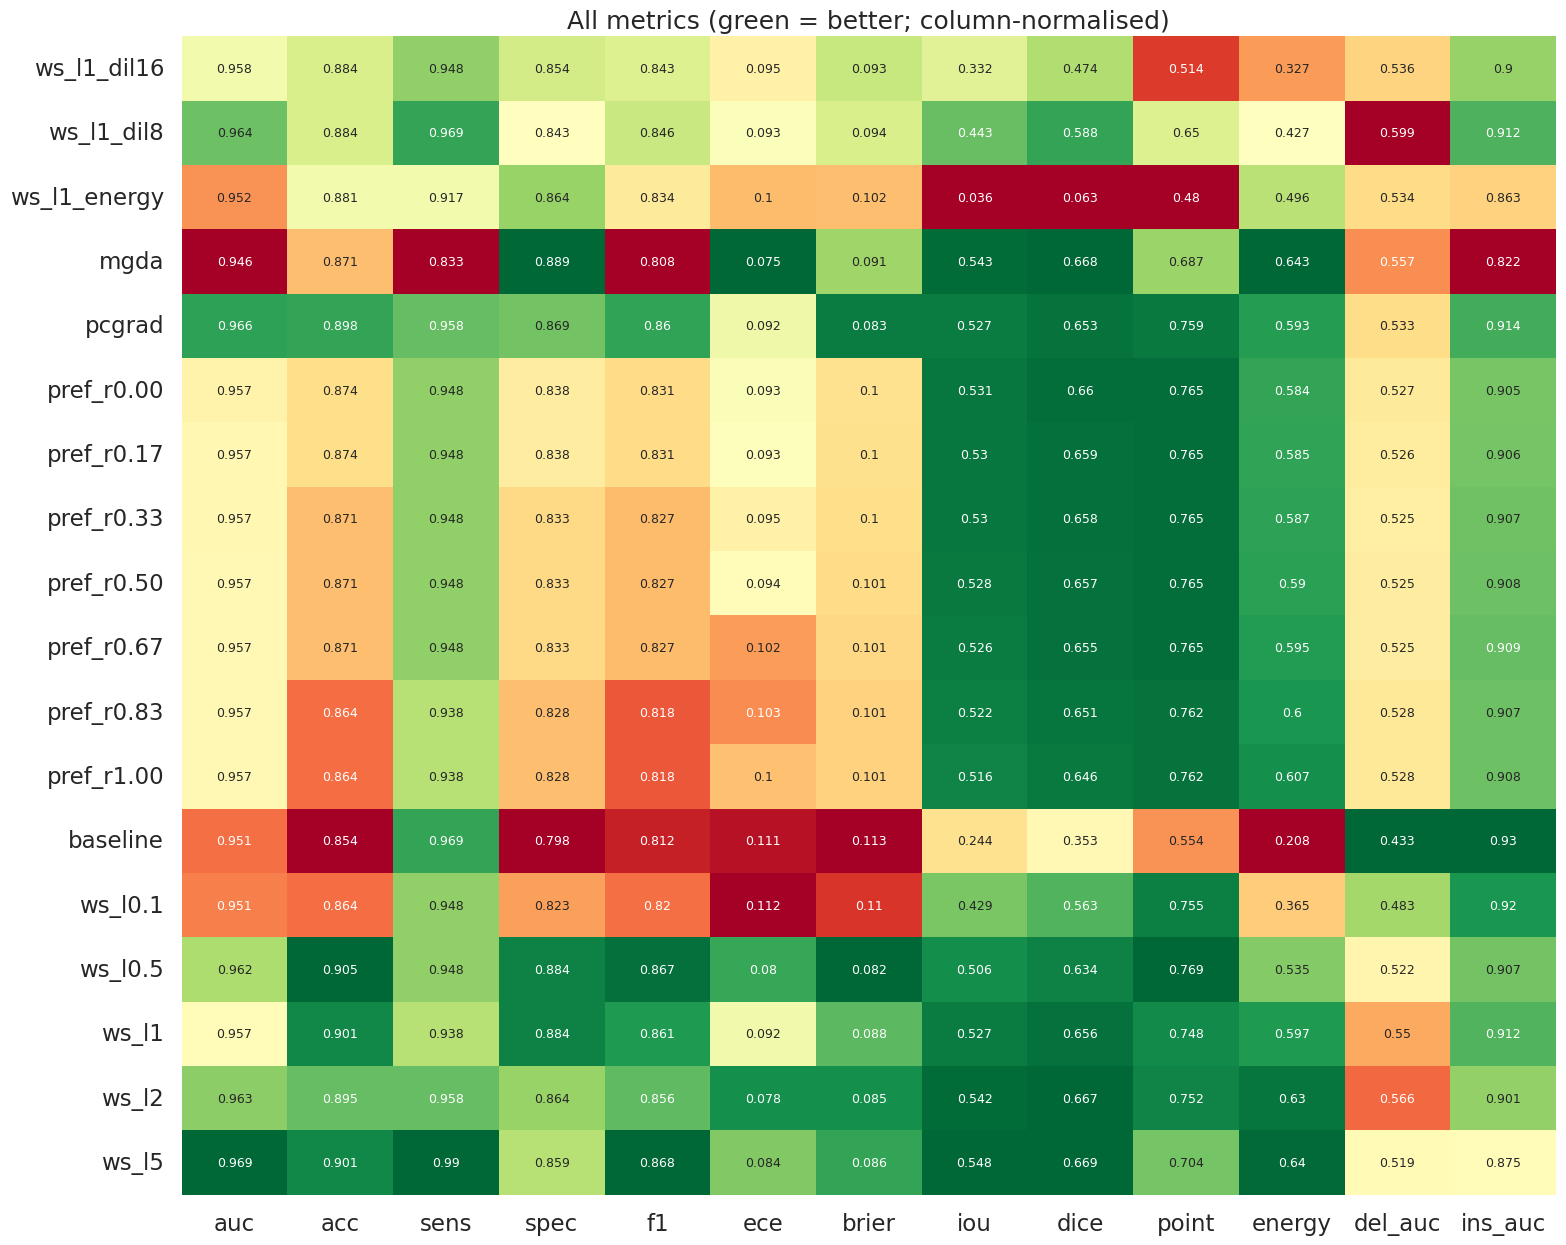

In [8]:
# ---------- 8. Summary table (mean +- std over seeds) ----------
cols = ['auc', 'acc', 'sens', 'spec', 'f1', 'ece', 'brier', 'iou', 'dice', 'point', 'energy', 'del_auc', 'ins_auc']
g = RES.groupby(['family', 'name'])[cols]
SUM = g.mean().round(3).astype(str) + ' ± ' + g.std().fillna(0).round(3).astype(str)
SUM.to_csv(f'{OUT}/summary_mean_std.csv'); display(SUM)
MEANS = RES.groupby(['family', 'name'])[cols].mean().reset_index()

fig, ax = plt.subplots(figsize=(16, 0.6 * len(MEANS) + 2))
hm = MEANS.set_index('name')[cols]; hmn = (hm - hm.min()) / (hm.max() - hm.min() + 1e-9)
for c in ['ece', 'brier', 'del_auc']: hmn[c] = 1 - hmn[c]          # lower is better -> flip colour
sns.heatmap(hmn, annot=hm.round(3), fmt='', cmap='RdYlGn', cbar=False, ax=ax, annot_kws={'size': 9})
ax.set_ylabel(''); ax.set_title('All metrics (green = better; column-normalised)')
plt.tight_layout(); plt.savefig(f'{FIG}/01_metrics_heatmap.png', dpi=200); plt.show()

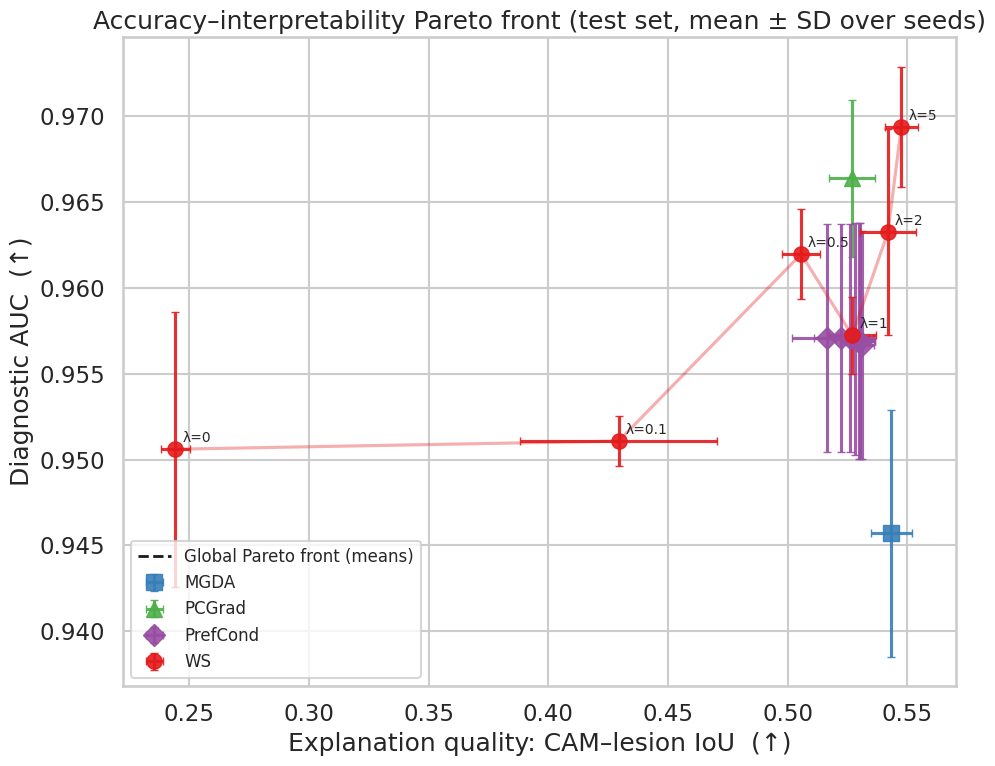

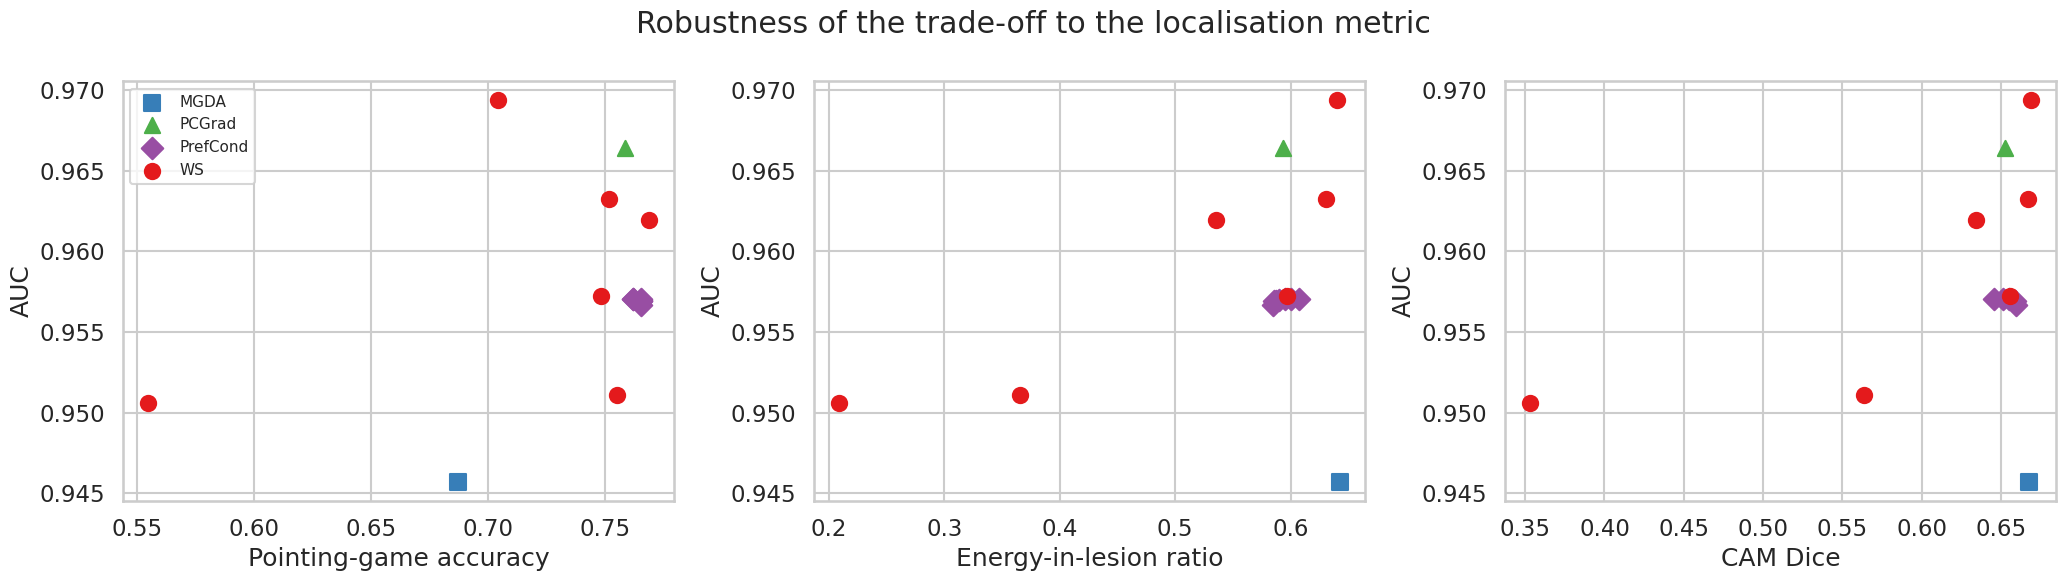

In [9]:
# ---------- 9. Pareto front: AUC vs. CAM-IoU ----------
def nondominated(P):                               # maximise both coordinates
    P = np.asarray(P); keep = []
    for i, p in enumerate(P):
        if not any((q >= p).all() and (q > p).any() for j, q in enumerate(P) if j != i): keep.append(i)
    return keep

ST = RES.groupby(['family', 'name'])[['auc', 'iou']].agg(['mean', 'std']).reset_index()
ST.columns = ['family', 'name', 'auc', 'auc_sd', 'iou', 'iou_sd']
ST = ST.fillna(0)
ST = ST[ST.family != 'Ablation'].reset_index(drop=True)
pal = dict(zip(['WS', 'MGDA', 'PCGrad', 'PrefCond'], sns.color_palette('Set1', 4)))
mk = dict(WS='o', MGDA='s', PCGrad='^', PrefCond='D')
fig, ax = plt.subplots(figsize=(10, 8))
for fam, d in ST.groupby('family'):
    ax.errorbar(d.iou, d.auc, xerr=d.iou_sd, yerr=d.auc_sd, fmt=mk[fam], color=pal[fam], ms=11, capsize=3, alpha=.9, label=fam)
    if fam in ('WS', 'PrefCond'):
        dd = d.sort_values('iou'); ax.plot(dd.iou, dd.auc, '-', color=pal[fam], alpha=.35)
for _, r in ST[ST.family == 'WS'].iterrows(): ax.annotate(r['name'].replace('ws_l', 'λ=').replace('baseline', 'λ=0'), (r.iou, r.auc), fontsize=10, xytext=(5, 5), textcoords='offset points')
nd = nondominated(ST[['iou', 'auc']].values); f_ = ST.iloc[nd].sort_values('iou')
ax.step(f_.iou, f_.auc, where='post', color='k', ls='--', lw=2, label='Global Pareto front (means)')
ax.set_xlabel('Explanation quality: CAM–lesion IoU  (↑)'); ax.set_ylabel('Diagnostic AUC  (↑)')
ax.set_title('Accuracy–interpretability Pareto front (test set, mean ± SD over seeds)'); ax.legend(loc='lower left', fontsize=12)
plt.tight_layout(); plt.savefig(f'{FIG}/02_pareto_front_auc_vs_iou.png', dpi=200); plt.show()

# secondary fronts: AUC vs pointing-game / energy / sens-spec
fig, axs = plt.subplots(1, 3, figsize=(21, 6))
for a, (xc, xl) in zip(axs, [('point', 'Pointing-game accuracy'), ('energy', 'Energy-in-lesion ratio'), ('dice', 'CAM Dice')]):
    d = MEANS[MEANS.family != 'Ablation']
    for fam, dd in d.groupby('family'): a.scatter(dd[xc], dd.auc, s=120, color=pal[fam], marker=mk[fam], label=fam)
    a.set_xlabel(xl); a.set_ylabel('AUC')
axs[0].legend(fontsize=11); plt.suptitle('Robustness of the trade-off to the localisation metric'); plt.tight_layout()
plt.savefig(f'{FIG}/03_pareto_alt_localisation_metrics.png', dpi=200); plt.show()

                      mean     std
method                            
All methods         0.2588  0.0035
MGDA                0.2421  0.0029
PCGrad              0.2457  0.0048
PrefCond (1 model)  0.2428  0.0049
WS (λ sweep)        0.2578  0.0038


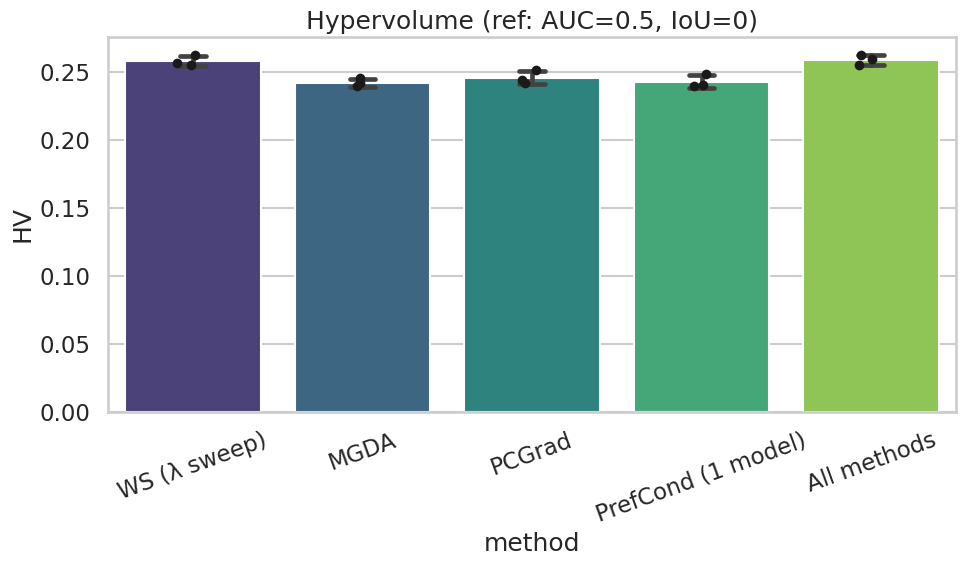

In [10]:
# ---------- 10. Hypervolume per family & seed ----------
def hv2d(points, ref=(0.5, 0.0)):
    pts = sorted([p for p in points if p[0] > ref[0] and p[1] > ref[1]], key=lambda p: -p[0]); hv, by = 0.0, ref[1]
    for x, y in pts:
        if y > by: hv += (x - ref[0]) * (y - by); by = y
    return hv
fam_names = {'WS (λ sweep)': lambda n, f: f == 'WS', 'MGDA': lambda n, f: f == 'MGDA', 'PCGrad': lambda n, f: f == 'PCGrad',
             'PrefCond (1 model)': lambda n, f: f == 'PrefCond', 'All methods': lambda n, f: f != 'Ablation'}
hv_rows = []
for seed in CFG['SEEDS']:
    d = RES[RES.seed == seed]
    for k, fn in fam_names.items():
        sel = d[[fn(n, f) for n, f in zip(d.name, d.family)]]
        hv_rows.append(dict(method=k, seed=seed, HV=hv2d(list(zip(sel.auc, sel.iou)))))
HV = pd.DataFrame(hv_rows); HV.to_csv(f'{OUT}/hypervolume.csv', index=False)
print(HV.groupby('method').HV.agg(['mean', 'std']).round(4))
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=HV, x='method', y='HV', errorbar='sd', capsize=.15, palette='viridis', ax=ax)
sns.stripplot(data=HV, x='method', y='HV', color='k', size=7, ax=ax)
ax.set_title('Hypervolume (ref: AUC=0.5, IoU=0)'); plt.xticks(rotation=20); plt.tight_layout()
plt.savefig(f'{FIG}/04_hypervolume.png', dpi=200); plt.show()

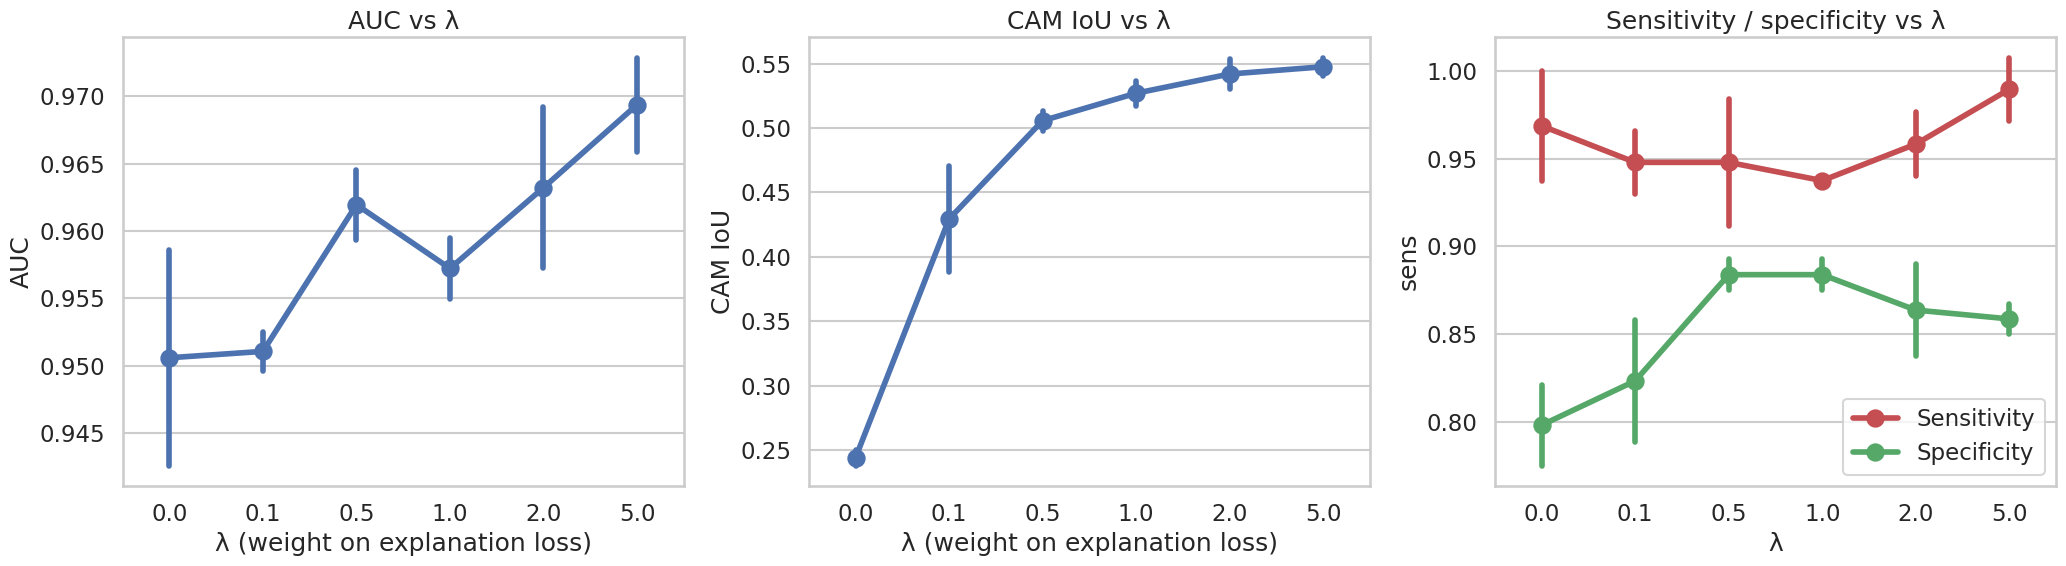

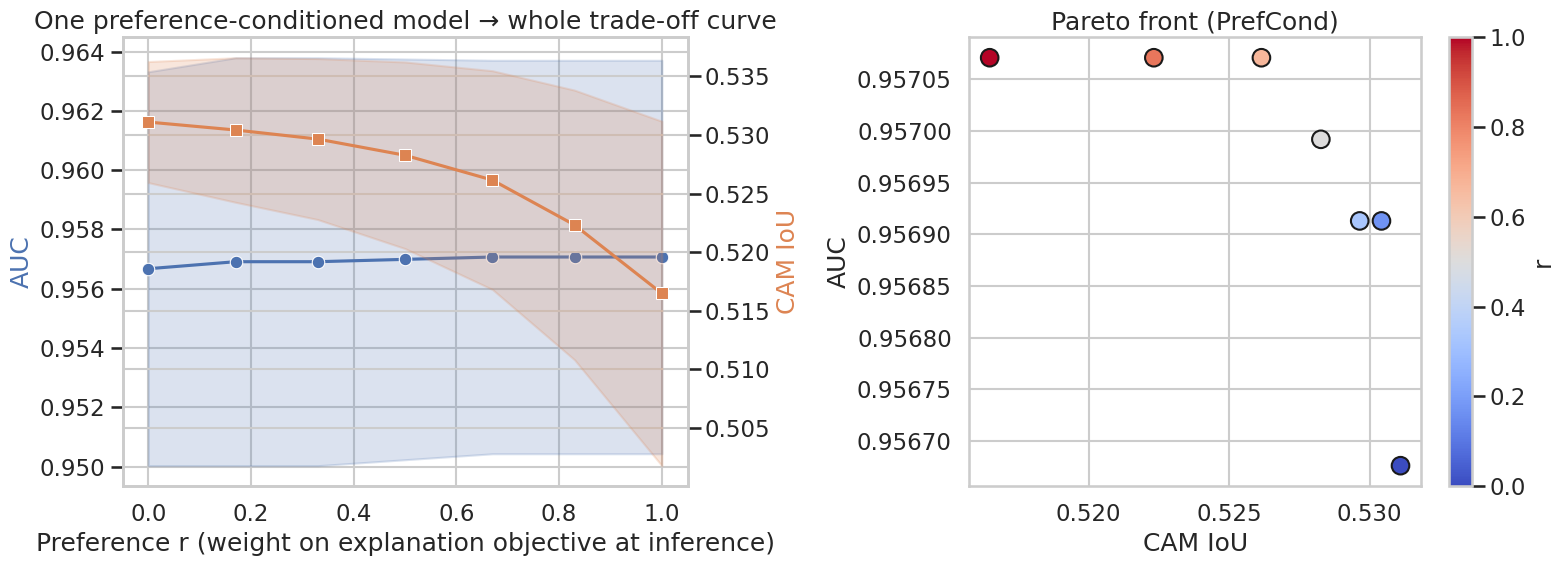

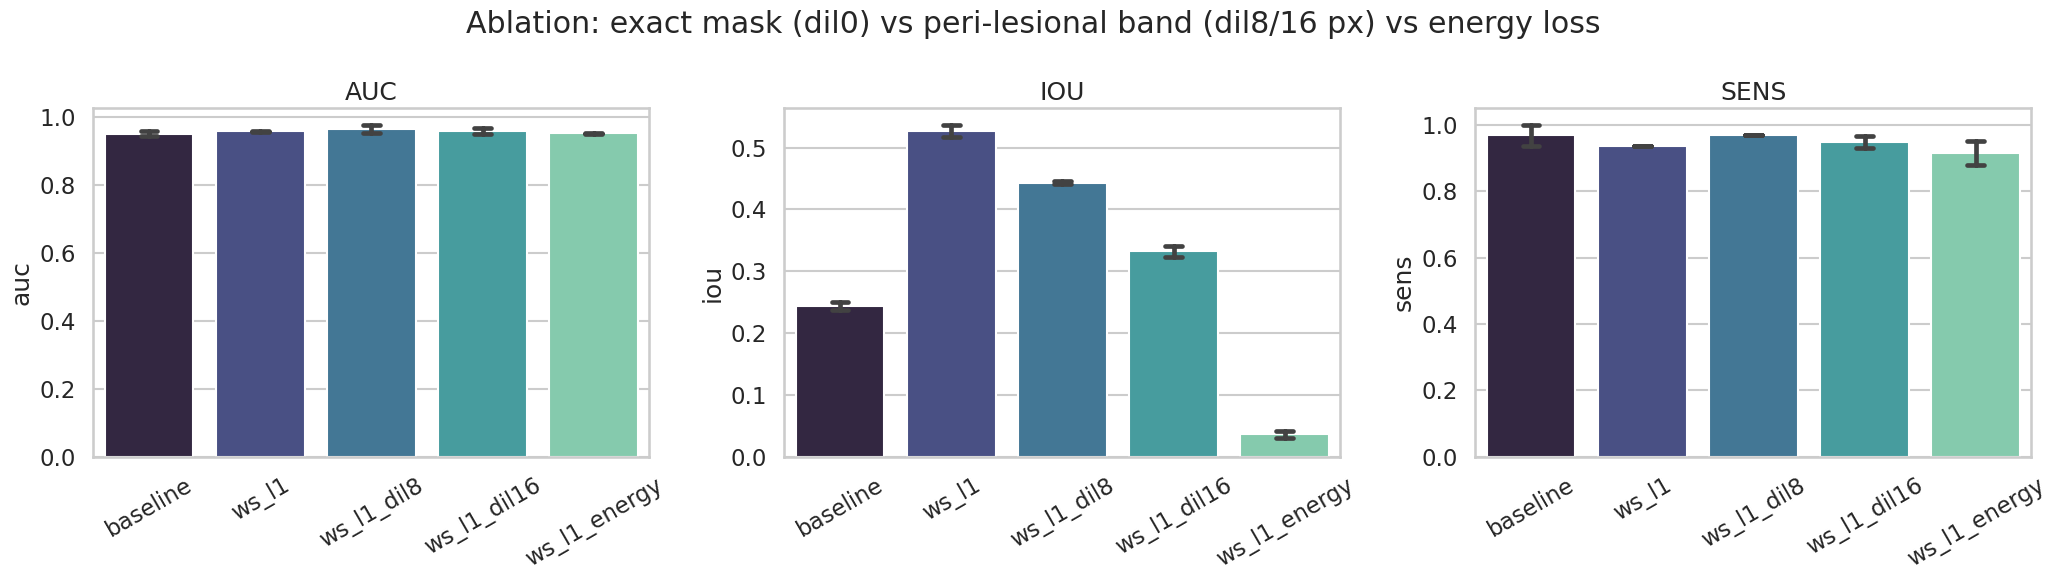

In [11]:
# ---------- 11. Lambda sweep, preference-conditioned front, ablations ----------
ws = RES[RES.name.isin(['baseline'] + [f'ws_l{l:g}' for l in CFG['LAMBDAS']])].copy()
ws['lam'] = ws.name.map(lambda n: 0.0 if n == 'baseline' else float(n.replace('ws_l', '')))
fig, ax = plt.subplots(1, 3, figsize=(21, 6))
for c, lab, a in [('auc', 'AUC', ax[0]), ('iou', 'CAM IoU', ax[1])]:
    sns.pointplot(data=ws, x='lam', y=c, errorbar='sd', ax=a, color='C0'); a.set_xlabel('λ (weight on explanation loss)'); a.set_ylabel(lab); a.set_title(f'{lab} vs λ')
sns.pointplot(data=ws, x='lam', y='sens', errorbar='sd', ax=ax[2], color='C3', label='Sensitivity')
sns.pointplot(data=ws, x='lam', y='spec', errorbar='sd', ax=ax[2], color='C2', label='Specificity'); ax[2].legend(); ax[2].set_xlabel('λ'); ax[2].set_title('Sensitivity / specificity vs λ')
plt.tight_layout(); plt.savefig(f'{FIG}/05_lambda_sweep.png', dpi=200); plt.show()

pf = RES[RES.family == 'PrefCond'].copy(); pf['r'] = pf.name.str.replace('pref_r', '').astype(float)
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
a2 = ax[0].twinx(); sns.lineplot(data=pf, x='r', y='auc', marker='o', color='C0', ax=ax[0], errorbar='sd'); sns.lineplot(data=pf, x='r', y='iou', marker='s', color='C1', ax=a2, errorbar='sd')
ax[0].set_ylabel('AUC', color='C0'); a2.set_ylabel('CAM IoU', color='C1'); ax[0].set_xlabel('Preference r (weight on explanation objective at inference)'); ax[0].set_title('One preference-conditioned model → whole trade-off curve')
sc = ax[1].scatter(pf.groupby('r').iou.mean(), pf.groupby('r').auc.mean(), c=sorted(pf.r.unique()), cmap='coolwarm', s=160, edgecolor='k')
plt.colorbar(sc, ax=ax[1], label='r'); ax[1].set_xlabel('CAM IoU'); ax[1].set_ylabel('AUC'); ax[1].set_title('Pareto front (PrefCond)')
plt.tight_layout(); plt.savefig(f'{FIG}/06_preference_conditioned_front.png', dpi=200); plt.show()

ab = RES[RES.name.isin(['baseline', 'ws_l1', 'ws_l1_dil8', 'ws_l1_dil16', 'ws_l1_energy'])]
fig, ax = plt.subplots(1, 3, figsize=(21, 6)); order = ['baseline', 'ws_l1', 'ws_l1_dil8', 'ws_l1_dil16', 'ws_l1_energy']
for a, c in zip(ax, ['auc', 'iou', 'sens']):
    sns.barplot(data=ab, x='name', y=c, order=order, errorbar='sd', capsize=.15, palette='mako', ax=a); a.set_xlabel(''); a.tick_params(axis='x', rotation=30); a.set_title(c.upper())
plt.suptitle('Ablation: exact mask (dil0) vs peri-lesional band (dil8/16 px) vs energy loss'); plt.tight_layout()
plt.savefig(f'{FIG}/07_ablation_mask_dilation_loss.png', dpi=200); plt.show()

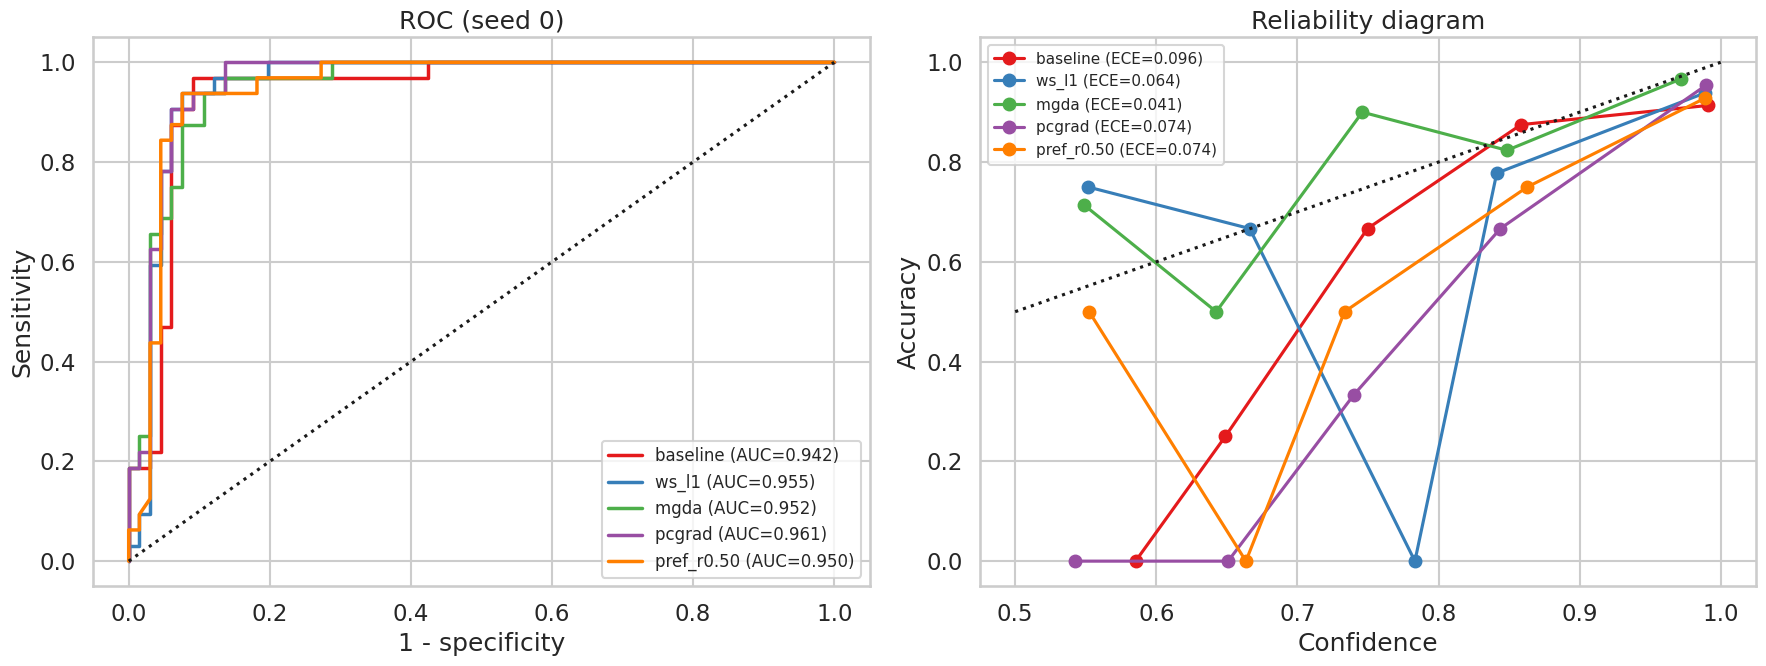

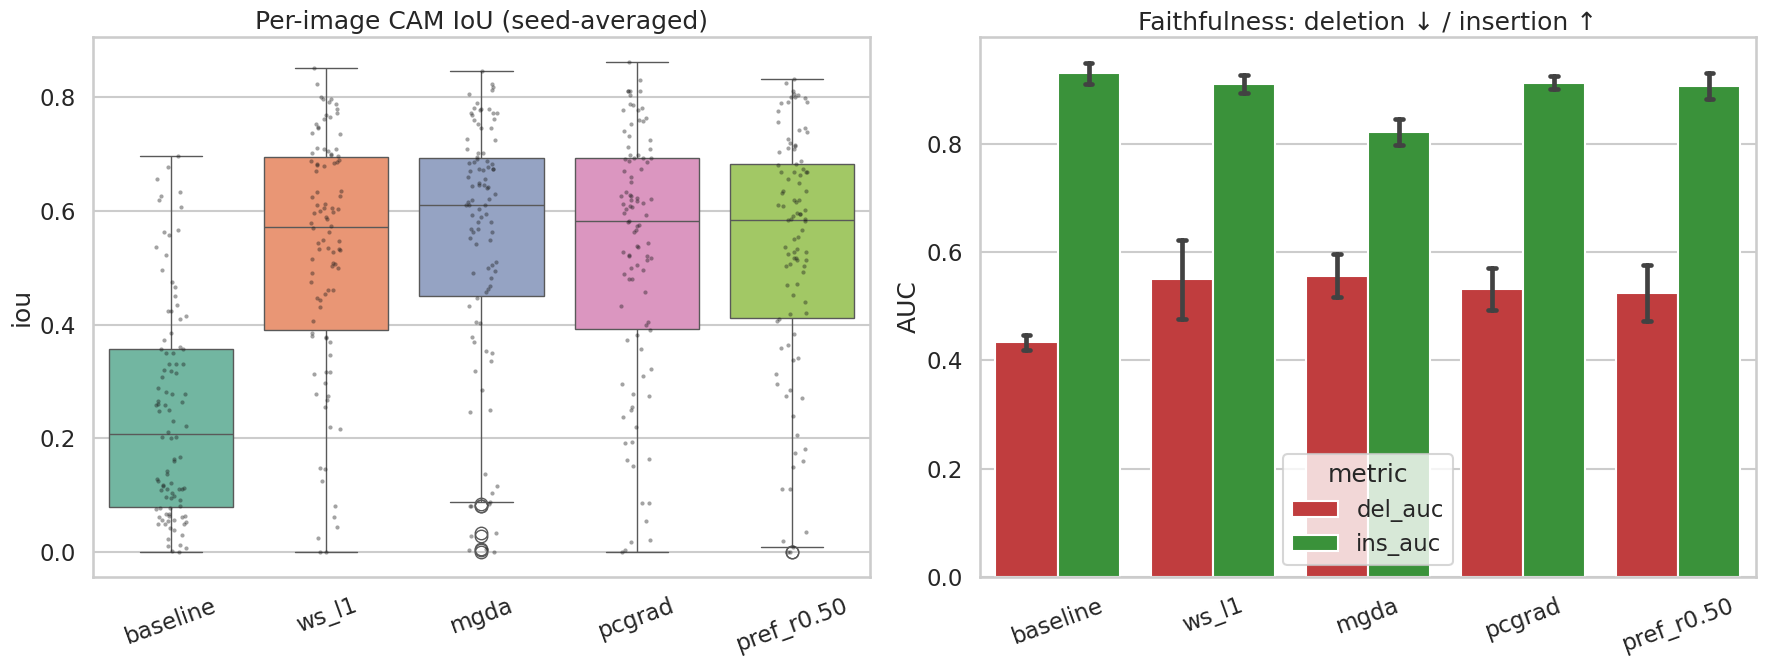

In [12]:
# ---------- 12. ROC, calibration, per-image IoU, faithfulness ----------
yte = DATA['yte'].cpu().numpy(); s0 = CFG['SEEDS'][0]; cmap5 = dict(zip(MAIN, sns.color_palette('Set1', 5)))
fig, ax = plt.subplots(1, 2, figsize=(18, 7))
for n in MAIN:
    p = PROBS[(n, s0)][:, 1]; fpr, tpr, _ = roc_curve(yte, p); ax[0].plot(fpr, tpr, lw=2.5, color=cmap5[n], label=f'{n} (AUC={roc_auc_score(yte, p):.3f})')
ax[0].plot([0, 1], [0, 1], 'k:'); ax[0].set_xlabel('1 - specificity'); ax[0].set_ylabel('Sensitivity'); ax[0].set_title(f'ROC (seed {s0})'); ax[0].legend(fontsize=12)
for n in MAIN:
    p = PROBS[(n, s0)]; conf = p.max(1); cor = (p.argmax(1) == yte).astype(float); e, cf, ac, cn = ece_bins(conf, cor, 5)
    ax[1].plot(cf, ac, 'o-', color=cmap5[n], label=f'{n} (ECE={e:.3f})')
ax[1].plot([0.5, 1], [0.5, 1], 'k:'); ax[1].set_xlabel('Confidence'); ax[1].set_ylabel('Accuracy'); ax[1].set_title('Reliability diagram'); ax[1].legend(fontsize=11)
plt.tight_layout(); plt.savefig(f'{FIG}/08_roc_and_calibration.png', dpi=200); plt.show()

box = pd.DataFrame([dict(name=n, iou=v) for n in MAIN for v in np.mean([PER_IMG[(n, s)] for s in CFG['SEEDS']], axis=0)])
fig, ax = plt.subplots(1, 2, figsize=(18, 7))
sns.boxplot(data=box, x='name', y='iou', palette='Set2', ax=ax[0]); sns.stripplot(data=box, x='name', y='iou', color='k', size=3, alpha=.4, ax=ax[0])
ax[0].set_title('Per-image CAM IoU (seed-averaged)'); ax[0].set_xlabel(''); ax[0].tick_params(axis='x', rotation=20)
fd = RES[RES.name.isin(MAIN)].melt(id_vars=['name', 'seed'], value_vars=['del_auc', 'ins_auc'], var_name='metric', value_name='AUC')
sns.barplot(data=fd, x='name', y='AUC', hue='metric', order=MAIN, errorbar='sd', capsize=.1, palette=['#d62728', '#2ca02c'], ax=ax[1])
ax[1].set_title('Faithfulness: deletion ↓ / insertion ↑'); ax[1].set_xlabel(''); ax[1].tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.savefig(f'{FIG}/09_perimage_iou_and_faithfulness.png', dpi=200); plt.show()

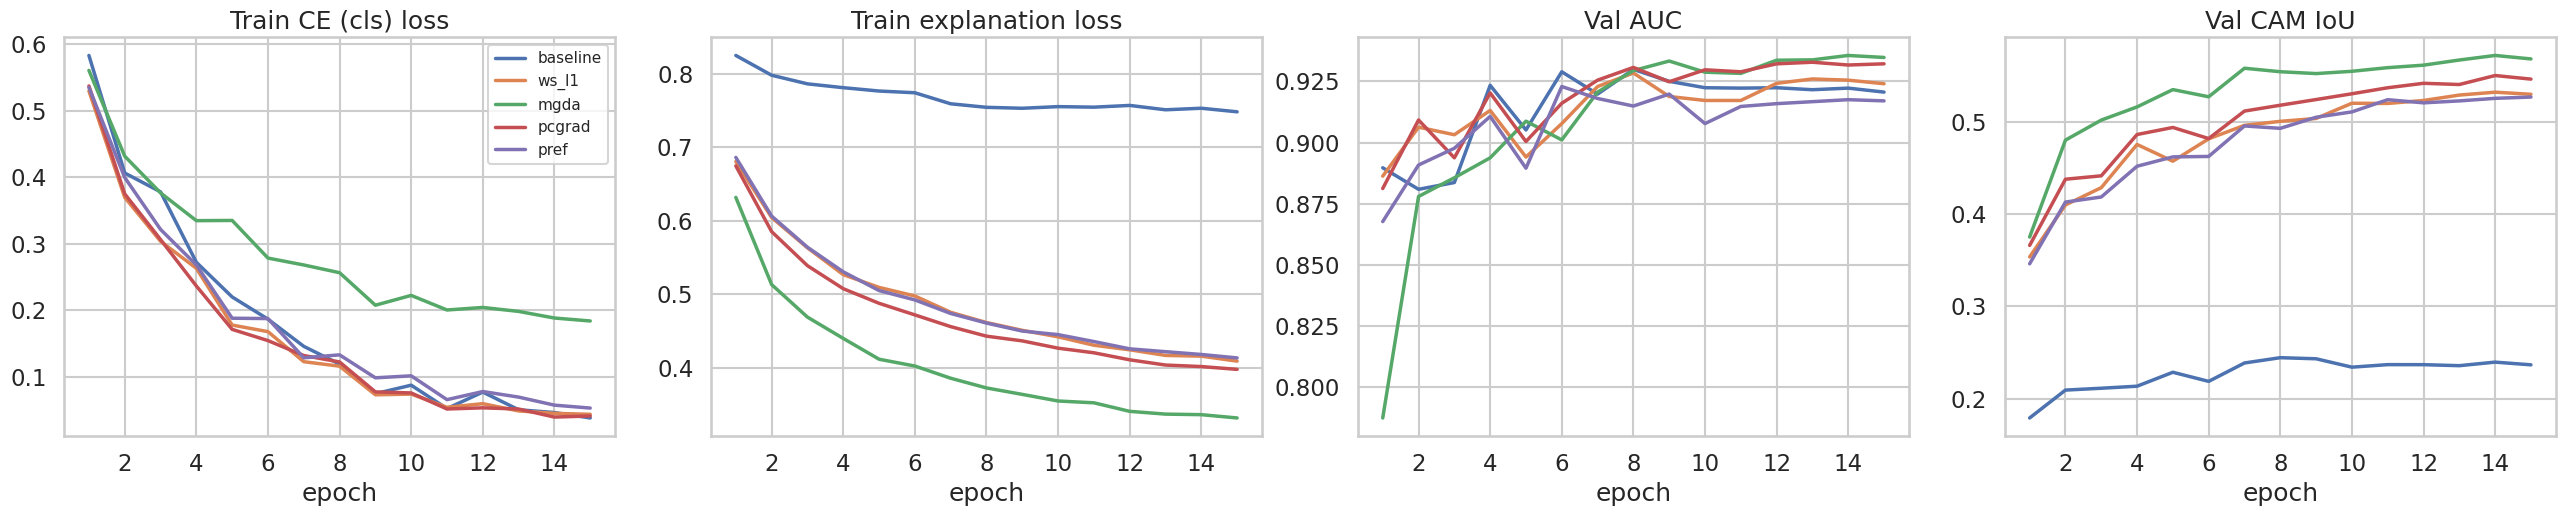

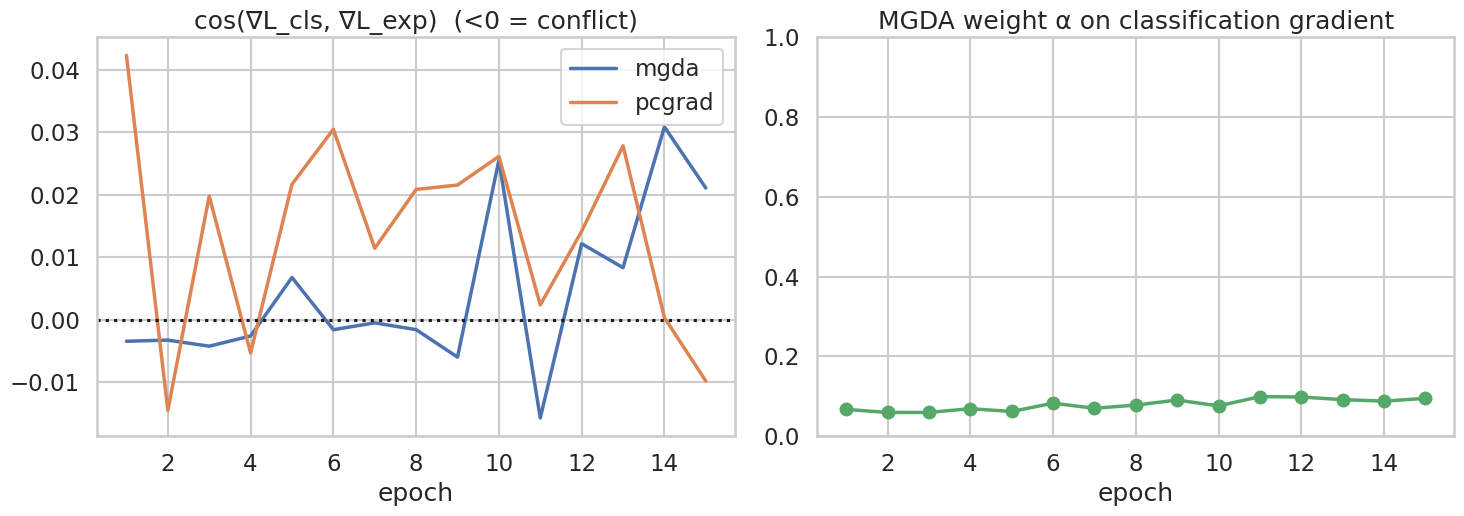

In [13]:
# ---------- 13. Training dynamics + gradient conflict ----------
fig, ax = plt.subplots(1, 4, figsize=(26, 5.5)); show = ['baseline', 'ws_l1', 'mgda', 'pcgrad', 'pref']
for n in show:
    h = pd.concat([HIST[(n, s)].assign(seed=s) for s in CFG['SEEDS']]).groupby('ep').mean()
    for a, c, t in zip(ax[:4], ['Lc', 'Le', 'val_auc', 'val_iou'], ['Train CE (cls) loss', 'Train explanation loss', 'Val AUC', 'Val CAM IoU']):
        a.plot(h.index, h[c], lw=2.5, label=n); a.set_title(t); a.set_xlabel('epoch')
ax[0].legend(fontsize=11); plt.tight_layout(); plt.savefig(f'{FIG}/10_training_curves.png', dpi=200); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
for n in ['mgda', 'pcgrad']:
    h = pd.concat([HIST[(n, s)] for s in CFG['SEEDS']]).groupby('ep').mean(); ax[0].plot(h.index, h.cos, lw=2.5, label=n)
ax[0].axhline(0, color='k', ls=':'); ax[0].set_title('cos(∇L_cls, ∇L_exp)  (<0 = conflict)'); ax[0].set_xlabel('epoch'); ax[0].legend()
h = pd.concat([HIST[('mgda', s)] for s in CFG['SEEDS']]).groupby('ep').mean(); ax[1].plot(h.index, h.alpha, 'g-o', lw=2.5)
ax[1].set_title('MGDA weight α on classification gradient'); ax[1].set_xlabel('epoch'); ax[1].set_ylim(0, 1)
plt.tight_layout(); plt.savefig(f'{FIG}/11_gradient_conflict.png', dpi=200); plt.show()

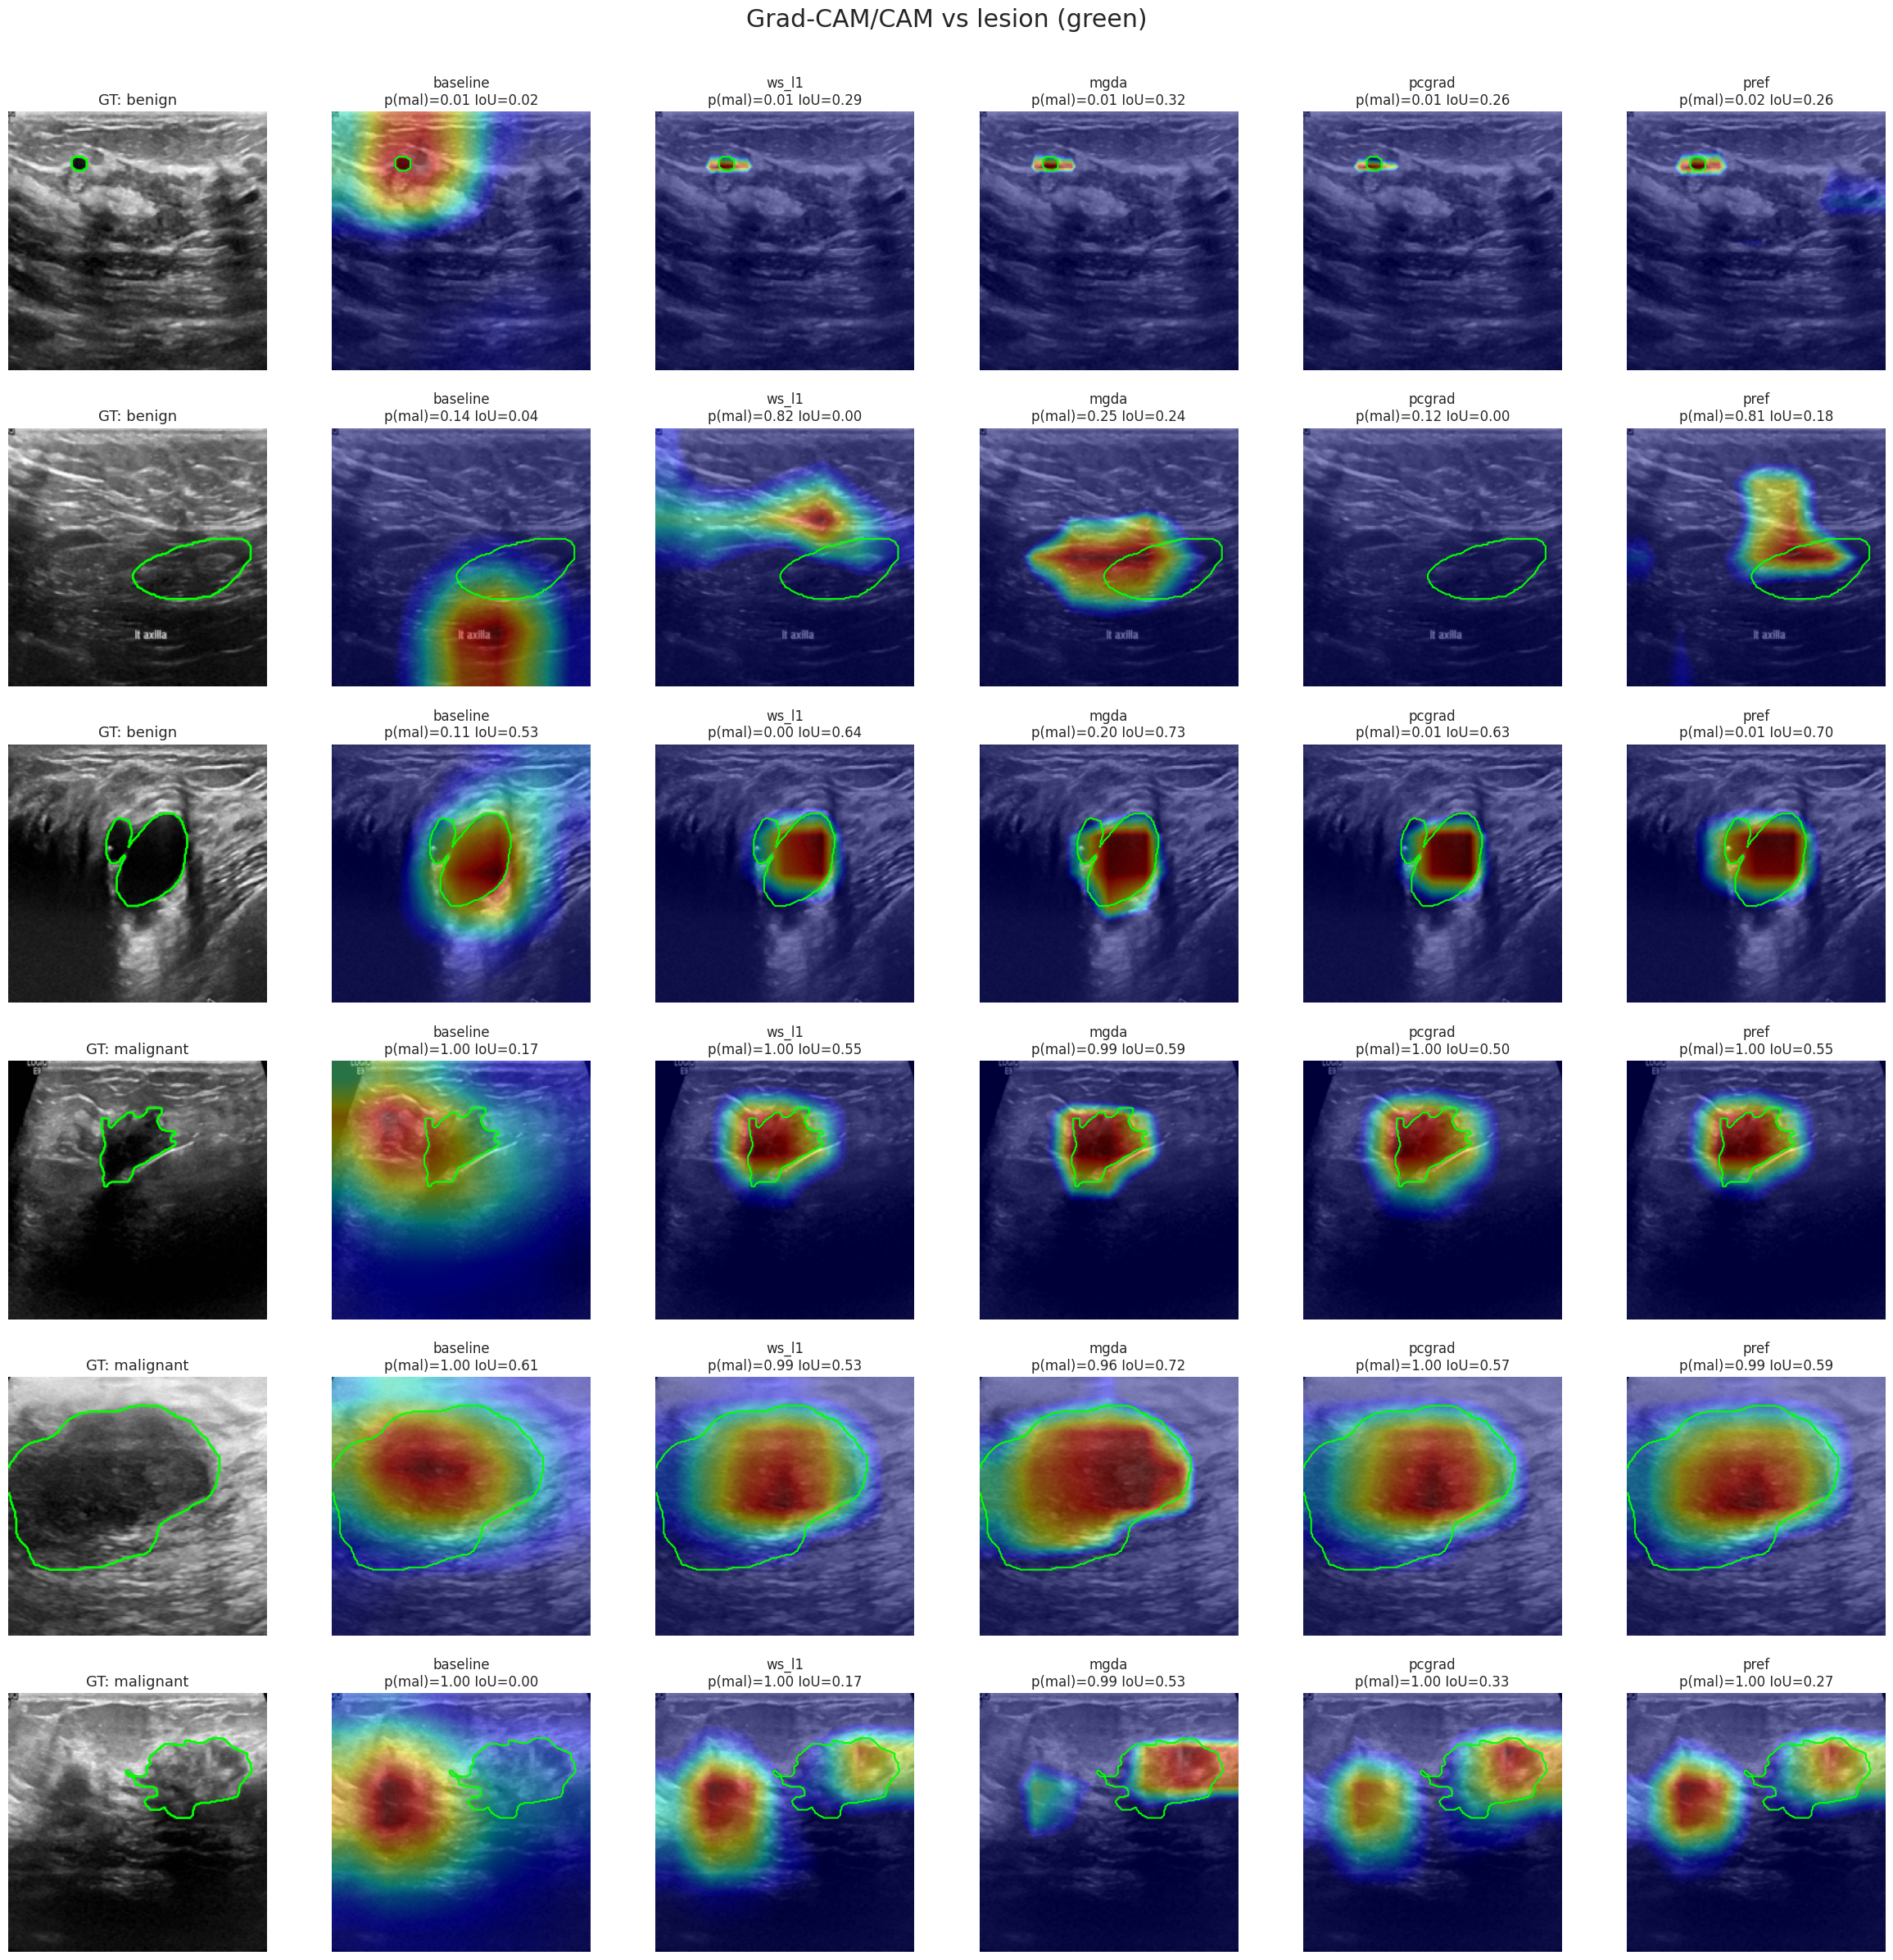

In [14]:
# ---------- 14. Qualitative CAM overlays (seed-0 models) ----------
te_y = DATA['yte'].cpu().numpy()
pick = list(np.where(te_y == 0)[0][:3]) + list(np.where(te_y == 1)[0][:3])
cols_ = ['baseline', 'ws_l1', 'mgda', 'pcgrad', 'pref']
CAMS = {}
for n in cols_:
    pr = [0.5, 0.5] if n == 'pref' else None
    p_, c_ = predict(MODELS[n], DATA['Xte'], pr); CAMS[n] = (p_.cpu().numpy(), c_.cpu().numpy())
fig, ax = plt.subplots(len(pick), len(cols_) + 1, figsize=(4 * (len(cols_) + 1), 4 * len(pick)))
for r, i in enumerate(pick):
    img, msk = DATA['Xte'][i, 0].cpu().numpy(), DATA['Mte'][i, 0].cpu().numpy()
    ax[r, 0].imshow(img, cmap='gray'); ax[r, 0].contour(msk, [0.5], colors='lime', linewidths=2); ax[r, 0].set_title(f'GT: {["benign", "malignant"][te_y[i]]}', fontsize=13)
    for c, n in enumerate(cols_):
        pr_, cm = CAMS[n]; ax[r, c + 1].imshow(img, cmap='gray'); ax[r, c + 1].imshow(cm[i, 0], cmap='jet', alpha=.45, vmin=0, vmax=1)
        ax[r, c + 1].contour(msk, [0.5], colors='lime', linewidths=1.5)
        iou = ((cm[i, 0] >= .5) & (msk > .5)).sum() / max(((cm[i, 0] >= .5) | (msk > .5)).sum(), 1)
        ax[r, c + 1].set_title(f'{n}\np(mal)={pr_[i, 1]:.2f} IoU={iou:.2f}', fontsize=12)
for a in ax.ravel(): a.axis('off')
plt.suptitle('Grad-CAM/CAM vs lesion (green)', y=1.0); plt.tight_layout(); plt.savefig(f'{FIG}/12_qualitative_cams.png', dpi=150); plt.show()

In [15]:
# ---------- 15. Statistics: paired Wilcoxon on per-image IoU, bootstrap AUC CIs, sanity checks ----------
base = np.mean([PER_IMG[('baseline', s)] for s in CFG['SEEDS']], axis=0); st = []
for n in MAIN[1:]:
    v = np.mean([PER_IMG[(n, s)] for s in CFG['SEEDS']], axis=0)
    st.append(dict(method=n, mean_IoU_gain=float((v - base).mean()), wilcoxon_p=float(wilcoxon(v, base).pvalue)))
ST_TEST = pd.DataFrame(st); ST_TEST.to_csv(f'{OUT}/wilcoxon_iou_vs_baseline.csv', index=False); display(ST_TEST)

rng = np.random.default_rng(0); ci = []
for n in MAIN:
    p = PROBS[(n, s0)][:, 1]; bs = []
    for _ in range(1000):
        b = rng.integers(0, len(yte), len(yte))
        if len(np.unique(yte[b])) == 2: bs.append(roc_auc_score(yte[b], p[b]))
    ci.append(dict(method=n, AUC=roc_auc_score(yte, p), lo=np.percentile(bs, 2.5), hi=np.percentile(bs, 97.5)))
CI = pd.DataFrame(ci); CI.to_csv(f'{OUT}/auc_bootstrap_ci.csv', index=False); display(CI.round(3))

san = []
for n in MAIN:
    pr = [0.5, 0.5] if n == 'pref_r0.50' else None; key = 'pref' if n == 'pref_r0.50' else n
    san.append(dict(method=n, mean_abs_spearman_after_randomisation=randomization_check(MODELS[key], DATA['Xte'], pr)))
SAN = pd.DataFrame(san); SAN.to_csv(f'{OUT}/sanity_randomisation.csv', index=False); display(SAN.round(3))   # lower = CAM depends on learned weights (passes)

,method,mean_IoU_gain,wilcoxon_p
0,ws_l1,0.282842,3.588821e-15
1,mgda,0.299174,3.691885e-15
2,pcgrad,0.282668,5.962986e-15
3,pref_r0.50,0.284134,3.204150e-15


,method,AUC,lo,hi
0,baseline,0.942,0.890,0.985
1,ws_l1,0.955,0.905,0.993
2,mgda,0.952,0.905,0.986
3,pcgrad,0.961,0.918,0.993
4,pref_r0.50,0.950,0.898,0.988


,method,mean_abs_spearman_after_randomisation
0,baseline,0.246
1,ws_l1,0.195
2,mgda,0.147
3,pcgrad,0.133
4,pref_r0.50,0.241


,lam,lr,dil,val_auc,val_iou,test_auc,test_iou,front
0,0.6019,0.0008,3,0.9066,0.4855,0.9148,0.5026,True
10,0.6019,0.0008,4,0.9247,0.4823,0.9408,0.4797,True
14,0.2110,0.0005,3,0.9340,0.4320,0.9574,0.4563,True
16,0.2012,0.0004,11,0.9350,0.3415,0.9602,0.3611,True


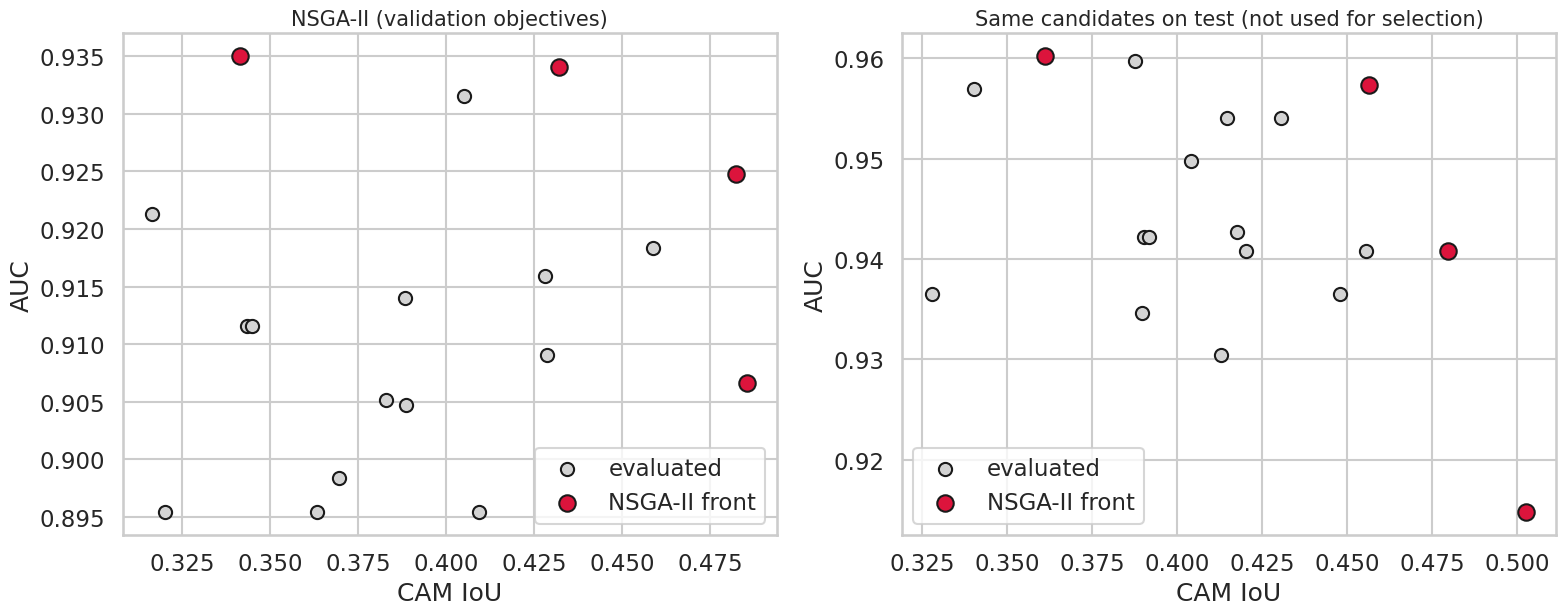

In [16]:
# ---------- 16. NSGA-II: hyper-parameter-level multi-objective search (lambda, lr, dilation) ----------
if CFG['RUN_NSGA2']:
    from pymoo.algorithms.moo.nsga2 import NSGA2
    from pymoo.core.problem import ElementwiseProblem
    from pymoo.optimize import minimize
    NSGA_LOG = []
    class HPO(ElementwiseProblem):
        def __init__(self): super().__init__(n_var=3, n_obj=2, xl=np.array([-1.5, -4.5, 0.0]), xu=np.array([1.0, -3.0, 20.0]))
        def _evaluate(self, x, out, *a, **k):
            lam, lr, dil = 10 ** x[0], 10 ** x[1], int(round(x[2]))
            m, h = train_run('ws', lam, dil, 'dice', 0, DATA, epochs=CFG['NSGA_EPOCHS'], lr=lr)
            va_auc, va_iou = h.val_auc.iloc[-1], h.val_iou.iloc[-1]          # selection uses VALIDATION only
            p, c = predict(m, DATA['Xte']); tm, _ = compute_metrics(p, DATA['yte'], c, DATA['Mte'])
            NSGA_LOG.append(dict(lam=lam, lr=lr, dil=dil, val_auc=va_auc, val_iou=va_iou, test_auc=tm['auc'], test_iou=tm['iou']))
            out['F'] = [1 - va_auc, 1 - va_iou]; del m; torch.cuda.empty_cache()
    res = minimize(HPO(), NSGA2(pop_size=CFG['NSGA_POP']), ('n_gen', CFG['NSGA_GEN']), seed=1, verbose=False)
    NG = pd.DataFrame(NSGA_LOG); NG['front'] = False
    for f_row in res.F:
        NG.loc[((NG.val_auc - (1 - f_row[0])).abs() < 1e-9) & ((NG.val_iou - (1 - f_row[1])).abs() < 1e-9), 'front'] = True
    NG.to_csv(f'{OUT}/nsga2_search_log.csv', index=False); display(NG[NG.front].round(4))
    fig, ax = plt.subplots(1, 2, figsize=(16, 6.5))
    for a, (xa, ya, t) in zip(ax, [('val_iou', 'val_auc', 'NSGA-II (validation objectives)'), ('test_iou', 'test_auc', 'Same candidates on test (not used for selection)')]):
        a.scatter(NG[xa], NG[ya], c='lightgray', s=90, edgecolor='k', label='evaluated'); a.scatter(NG[NG.front][xa], NG[NG.front][ya], c='crimson', s=140, edgecolor='k', label='NSGA-II front')
        a.set_xlabel('CAM IoU'); a.set_ylabel('AUC'); a.set_title(t, fontsize=15); a.legend()
    plt.tight_layout(); plt.savefig(f'{FIG}/13_nsga2_front.png', dpi=200); plt.show()

[confounder seed 0] baseline done
[confounder seed 0] ws_l1 done
[confounder seed 0] ws_l5 done
[confounder seed 0] mgda done
[confounder seed 1] baseline done
[confounder seed 1] ws_l1 done
[confounder seed 1] ws_l5 done
[confounder seed 1] mgda done
[confounder seed 2] baseline done
[confounder seed 2] ws_l1 done
[confounder seed 2] ws_l5 done
[confounder seed 2] mgda done


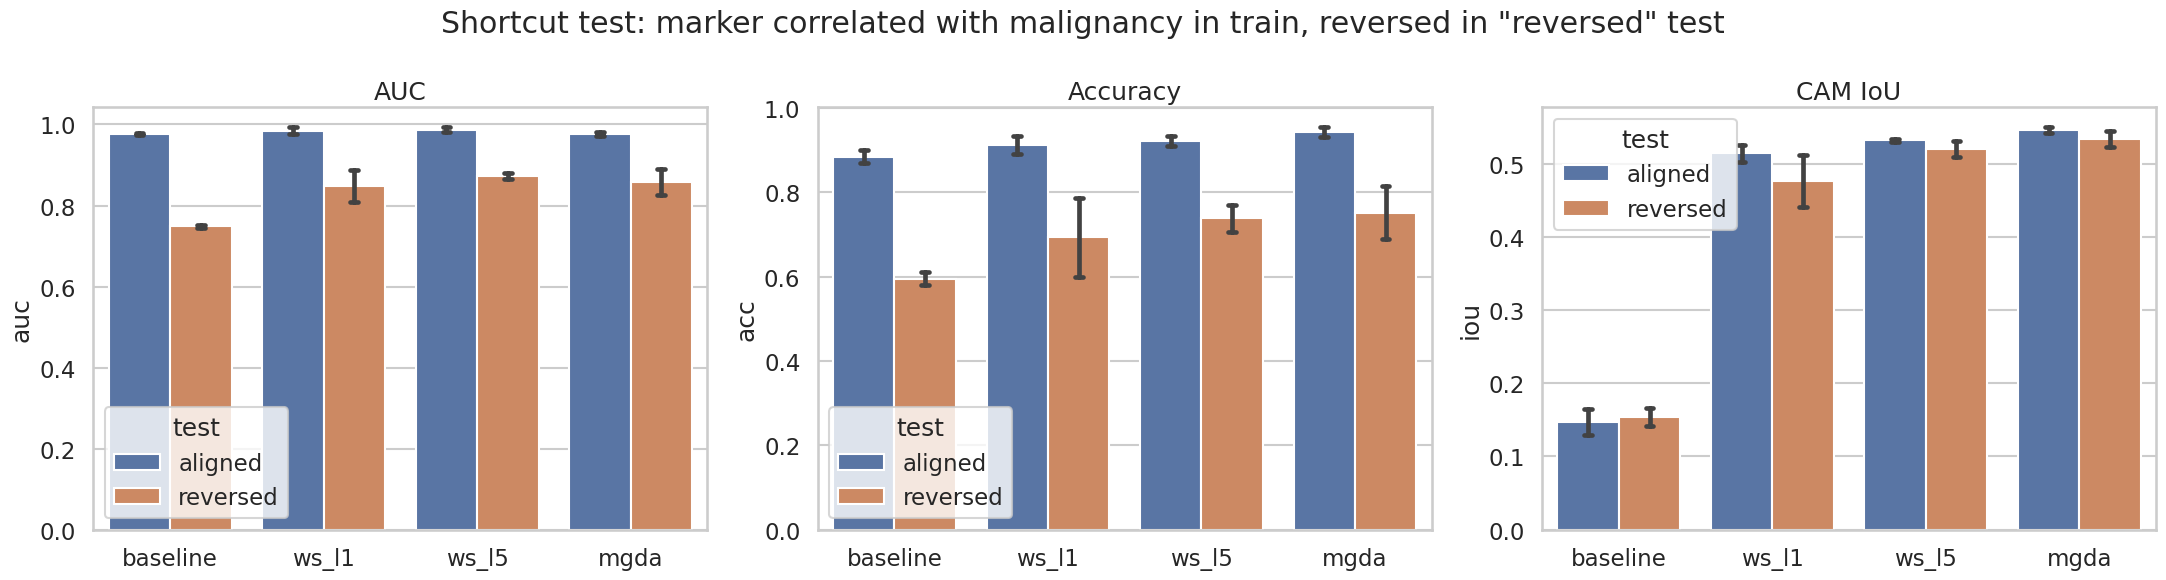

auc    acc    iou
method   test                         
baseline aligned   0.977  0.884  0.147
         reversed  0.749  0.595  0.154
mgda     aligned   0.977  0.942  0.546
         reversed  0.858  0.752  0.534
ws_l1    aligned   0.985  0.912  0.514
         reversed  0.847  0.694  0.476
ws_l5    aligned   0.987  0.922  0.532
         reversed  0.873  0.738  0.520

In [17]:
# ---------- 17. Shortcut-learning experiment: synthetic confounder (a bright "caliper" marker) ----------
# Train/val: marker appears with 90% probability on MALIGNANT images. Test-aligned: same rule.
# Test-reversed: marker appears with 90% probability on BENIGN images -> a shortcut-reliant model collapses.
if CFG['RUN_CONFOUNDER']:
    def add_marker(X, flag):
        X = X.clone(); X[flag, :, 8:28, 8:28] = 255; return X
    def marker_flags(y, p_mal, seed):
        g = torch.Generator().manual_seed(seed); u = torch.rand(len(y), generator=g)
        return torch.where(y == 1, u < p_mal, u < (1 - p_mal))
    yv = y_all.clone(); Xc = X_all.clone()
    flag = torch.zeros(N, dtype=torch.bool)
    for ii, ps, sd in [(i_tr, .9, 1), (i_va, .9, 2), (i_te, .9, 3)]: flag[ii] = marker_flags(y_all[ii], ps, sd)
    Xc = add_marker(X_all, flag); DATA_C = make_data(Xc, M_all, y_all)
    Xrev = X_all.clone(); fr_ = marker_flags(y_all[i_te], 0.1, 3)                 # reversed correlation on test
    Xrev[i_te] = add_marker(X_all[i_te], fr_); Xte_rev = Xrev[i_te].to(DEVICE)
    cf_rows = []
    for seed in CFG['SEEDS']:
        for name, method, lam in [('baseline', 'ws', 0.0), ('ws_l1', 'ws', 1.0), ('ws_l5', 'ws', 5.0), ('mgda', 'mgda', 1)]:
            m, _ = train_run(method, lam, 0, 'dice', seed, DATA_C)
            for split, Xs in [('aligned', DATA_C['Xte']), ('reversed', Xte_rev)]:
                p, c = predict(m, Xs); mm, _ = compute_metrics(p, DATA_C['yte'], c, DATA_C['Mte'])
                cf_rows.append(dict(method=name, seed=seed, test=split, auc=mm['auc'], acc=mm['acc'], iou=mm['iou']))
            print(f'[confounder seed {seed}] {name} done'); del m; torch.cuda.empty_cache()
    CF = pd.DataFrame(cf_rows); CF.to_csv(f'{OUT}/confounder_experiment.csv', index=False)
    fig, ax = plt.subplots(1, 3, figsize=(22, 6))
    for a, c, t in zip(ax, ['auc', 'acc', 'iou'], ['AUC', 'Accuracy', 'CAM IoU']):
        sns.barplot(data=CF, x='method', y=c, hue='test', errorbar='sd', capsize=.1, palette=['#4c72b0', '#dd8452'], ax=a); a.set_title(t); a.set_xlabel('')
    plt.suptitle('Shortcut test: marker correlated with malignancy in train, reversed in "reversed" test'); plt.tight_layout()
    plt.savefig(f'{FIG}/14_confounder_shortcut_test.png', dpi=200); plt.show()
    display(CF.groupby(['method', 'test'])[['auc', 'acc', 'iou']].mean().round(3))

In [19]:
# ---------- 18. Automatic findings + export ----------
M_ = MEANS[MEANS.family != 'Ablation']
b_auc, b_iou = M_.loc[M_.auc.idxmax()], M_.loc[M_.iou.idxmax()]
print(f"Highest AUC : {b_auc['name']}  (AUC={b_auc['auc']:.3f}, IoU={b_auc['iou']:.3f})")
print(f"Highest IoU : {b_iou['name']}  (AUC={b_iou['auc']:.3f}, IoU={b_iou['iou']:.3f})")

hv_mean = HV.groupby('method').HV.mean().drop('All methods')
print(f"Best hypervolume family: {hv_mean.idxmax()} (HV={float(hv_mean.max()):.4f})")
print('\nHypervolume by family:\n', hv_mean.round(4).to_string())

base_ = M_[M_.name == 'baseline'].iloc[0]
print(f"\nBaseline: AUC={base_['auc']:.3f}, IoU={base_['iou']:.3f}")

print('\nTables: ', sorted(os.listdir(OUT)), '\nFigures:', sorted(os.listdir(FIG)))
shutil.make_archive('bus_multiobjective_results', 'zip', OUT)
try:
    from google.colab import files
    files.download('bus_multiobjective_results.zip')
except Exception as e:
    print('Download manually:', e)

Highest AUC : ws_l5  (AUC=0.969, IoU=0.548)
Highest IoU : ws_l5  (AUC=0.969, IoU=0.548)
Best hypervolume family: WS (λ sweep) (HV=0.2578)

Hypervolume by family:
 method
MGDA                  0.2421
PCGrad                0.2457
PrefCond (1 model)    0.2428
WS (λ sweep)          0.2578

Baseline: AUC=0.951, IoU=0.244

Tables:  ['all_runs_test_metrics.csv', 'auc_bootstrap_ci.csv', 'confounder_experiment.csv', 'figs', 'hypervolume.csv', 'nsga2_search_log.csv', 'sanity_randomisation.csv', 'summary_mean_std.csv', 'wilcoxon_iou_vs_baseline.csv'] 
Figures: ['00_dataset_samples.png', '01_metrics_heatmap.png', '02_pareto_front_auc_vs_iou.png', '03_pareto_alt_localisation_metrics.png', '04_hypervolume.png', '05_lambda_sweep.png', '06_preference_conditioned_front.png', '07_ablation_mask_dilation_loss.png', '08_roc_and_calibration.png', '09_perimage_iou_and_faithfulness.png', '10_training_curves.png', '11_gradient_conflict.png', '12_qualitative_cams.png', '13_nsga2_front.png', '14_confounder_short

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>